# Bitcoin am Wochenende als Signal für den QQQ-Eröffnungsgap

In diesem Notebook untersuchen wir, ob Bitcoin-Bewegungen während des
Wochenendes zusammen mit Sentiment- und Makroindikatoren den
Eröffnungsgap von QQQ am folgenden Montag prognostizieren können.

**Primäres Ziel:** logarithmische Rendite vom QQQ-Schlusskurs am Freitag
zum QQQ-Eröffnungskurs am Montag.

**Zusätzliche Sicht:** Aus der numerischen Prognose leiten wir ab, ob QQQ
höher oder tiefer eröffnet. QQQ-Volumen und weitere Aktien sind bewusst
nicht Teil der Challenge.

Wir verwenden Daten bis Ende 2024 für EDA und Modellentwicklung. Daten ab
2025 bleiben als finaler Holdout unangetastet. Der aktuelle Notebook-Stand
enthält Setup, Datenbezug, zeitliche Ausrichtung, Ziel- und
Feature-Konstruktion sowie eine erste explorative Analyse.

## 1. Fragestellung und Vorgehen

### Erklärung

Unser Prognosezeitpunkt liegt am Sonntagabend. Wir verwenden nur
Informationen, die zu diesem Zeitpunkt bereits verfügbar sind. Die
numerische Zielvariable lautet:

$$
y_t = r^{\mathrm{gap}}_t
= \log\left(
\frac{Open^{QQQ}_{Monday,t}}{Close^{QQQ}_{Friday,t}}
\right).
$$

Für die verständliche Darstellung rechnen wir den Gap zusätzlich in
Prozent um:

$$
Gap^{\%}_t = 100\left(\exp(y_t)-1\right).
$$

Aus dem Vorzeichen erhalten wir später die Richtung:

$$
Direction_t = \mathbb{1}(y_t > 0).
$$

Die Kernfrage beantworten wir mit einem kontrollierten Vergleich: Ein
Modell verwendet QQQ-Historie, Fear & Greed, VIX und DXY. Das zweite
Modell erhält zusätzlich die Bitcoin-Wochenendmerkmale. So messen wir den
zusätzlichen Prognosewert von Bitcoin und nicht nur die Güte eines
einzelnen Algorithmus.

### Interpretation

Wir formulieren die Aufgabe als Regression. Dadurch können einfache
statistische Methoden, XGBoost und Chronos-2 dieselbe Zielvariable
prognostizieren. Die Richtungsgenauigkeit ist eine zweite, leicht
verständliche Auswertung derselben Prognosen und keine separate
Klassifikationspipeline.

## 2. Setup

### Erklärung

Wir bündeln alle veränderbaren Parameter in einer sichtbaren Zelle.
`DATA_END_DATE` ist exklusiv: Der Datensatz enthält nur Beobachtungen vor
diesem Datum. Der feste Stichtag sorgt dafür, dass spätere Wiederholungen
denselben historischen Ausschnitt verwenden.

Alle Zeitstempel werden intern in UTC gespeichert. Das Wochenende
definieren wir in `America/New_York`, weil sich QQQ nach den
US-Börsenzeiten richtet. Für Chronos-2 wählen wir auf Apple Silicon später
automatisch MPS, sofern es verfügbar ist. Die Datenaufbereitung läuft auf
der CPU.

In [1]:
from importlib.metadata import PackageNotFoundError, version
from io import BytesIO
from pathlib import Path
from zipfile import ZipFile
import os
import platform
import random
import warnings

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import yfinance as yf

# Keep all configuration visible and reproducible
RANDOM_SEED = 42
START_DATE = "2018-02-01"
DATA_END_DATE = "2026-07-01"  # Exclusive; monthly Binance archive is complete
HOLDOUT_START = pd.Timestamp("2025-01-01")
VALIDATION_YEARS = [2021, 2022, 2023, 2024]
FORECAST_TIMEZONE = "America/New_York"
BINANCE_SYMBOL = "BTCUSDT"
BINANCE_INTERVAL = "1h"
CHRONOS_MODEL_ID = "amazon/chronos-2"
# Repeated macOS walk-forward fits are more stable with one OpenMP worker
XGBOOST_N_JOBS = 1
os.environ["OMP_NUM_THREADS"] = str(XGBOOST_N_JOBS)

# Validate the fixed and fully completed data range
data_end_timestamp = pd.Timestamp(DATA_END_DATE)
current_utc_day = pd.Timestamp.now(tz="UTC").normalize().tz_localize(None)
assert data_end_timestamp <= current_utc_day

# Resolve paths from the repository root or the notebooks folder
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
BINANCE_CACHE_DIR = RAW_DATA_DIR / "binance" / BINANCE_SYMBOL / BINANCE_INTERVAL
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
BINANCE_CACHE_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Make random operations reproducible
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Use one consistent visual language throughout the notebook
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams.update(
    {
        "figure.figsize": (12, 5),
        "axes.titlesize": 14,
        "axes.labelsize": 11,
        "legend.frameon": False,
        "figure.dpi": 110,
    }
)
VIRIDIS = plt.colormaps["viridis"]
COLORS = {
    "qqq": VIRIDIS(0.12),
    "btc": VIRIDIS(0.38),
    "fear_greed": VIRIDIS(0.58),
    "vix": VIRIDIS(0.74),
    "dxy": VIRIDIS(0.90),
}

# Detect MPS without moving pandas work away from the CPU
try:
    import torch

    TORCH_VERSION = torch.__version__
    DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
except ImportError:
    torch = None
    TORCH_VERSION = "nicht installiert"
    DEVICE = "cpu"


def installed_version(package_name):
    # Return one version string for the reproducibility table
    try:
        return version(package_name)
    except PackageNotFoundError:
        return "nicht installiert"


environment_table = pd.DataFrame(
    {
        "Komponente": [
            "Python",
            "Betriebssystem",
            "Prozessor",
            "PyTorch",
            "Gewähltes Gerät",
            "Forecast-Zeitzone",
            "Erster Datentag",
            "Exklusiver Datenstichtag",
            "Holdout ab",
            "pandas",
            "yfinance",
            "statsmodels",
            "XGBoost",
            "chronos-forecasting",
        ],
        "Wert": [
            platform.python_version(),
            platform.platform(),
            platform.machine(),
            TORCH_VERSION,
            DEVICE,
            FORECAST_TIMEZONE,
            START_DATE,
            DATA_END_DATE,
            HOLDOUT_START.date(),
            installed_version("pandas"),
            installed_version("yfinance"),
            installed_version("statsmodels"),
            installed_version("xgboost"),
            installed_version("chronos-forecasting"),
        ],
    }
)
display(environment_table)

,Komponente,Wert
0,Python,3.11.13
1,Betriebssystem,macOS-26.5.2-arm64-arm-64bit
2,Prozessor,arm64
3,PyTorch,2.13.0
4,Gewähltes Gerät,mps
5,Forecast-Zeitzone,America/New_York
6,Erster Datentag,2018-02-01
7,Exklusiver Datenstichtag,2026-07-01
8,Holdout ab,2025-01-01
9,pandas,3.0.3


### Interpretation

Die Tabelle dokumentiert den festen Datenzeitraum und die tatsächlich
verwendete Softwareumgebung. MPS ist ausschliesslich für die spätere
Chronos-2-Inferenz vorgesehen. pandas, statsmodels und XGBoost bleiben
auf der CPU.

## 3. Daten laden und prüfen

### Erklärung

Für Bitcoin benötigen wir stündliche Daten, damit das Wochenende exakt
nach dem QQQ-Börsenschluss abgegrenzt werden kann. Wir laden monatliche
`BTCUSDT`-Dateien aus dem öffentlichen Binance-Archiv und speichern sie
lokal. QQQ, VIX und DXY beziehen wir über `yfinance`; Fear & Greed über
die API von Alternative.me.

| Inhalt | Quelle / Symbol | Verwendung |
|---|---|---|
| Bitcoin OHLCV | Binance `BTCUSDT`, 1 Stunde | Wochenendmerkmale |
| Nasdaq-100 ETF | Yahoo `QQQ` | Ziel und eigene Historie |
| Volatilitätsindex | Yahoo `^VIX` | Marktunsicherheit |
| US-Dollar-Index | Yahoo `DX-Y.NYB` | Makroumfeld |
| Fear & Greed | Alternative.me | Krypto-Sentiment |

Binance speichert ältere Zeitstempel in Millisekunden und neuere Dateien
teilweise in Mikrosekunden. Wir erkennen die Einheit pro Datei anhand der
Grössenordnung, anstatt eine feste Einheit anzunehmen.

In [2]:
BINANCE_COLUMNS = [
    "open_time",
    "open",
    "high",
    "low",
    "close",
    "volume",
    "close_time",
    "quote_volume",
    "trade_count",
    "taker_buy_base_volume",
    "taker_buy_quote_volume",
    "ignore",
]


def parse_binance_time(values):
    # Detect millisecond or microsecond Unix timestamps per archive file
    numeric_values = pd.to_numeric(values, errors="coerce")
    non_missing = numeric_values.dropna()
    assert not non_missing.empty, "Binance-Datei ohne gültige Zeitstempel"
    unit = "us" if non_missing.median() >= 10**14 else "ms"
    return pd.to_datetime(numeric_values, unit=unit, utc=True)


def read_binance_month(month_start):
    # Reuse the original monthly ZIP so every download stays traceable
    month_label = month_start.strftime("%Y-%m")
    filename = f"{BINANCE_SYMBOL}-{BINANCE_INTERVAL}-{month_label}.zip"
    cache_path = BINANCE_CACHE_DIR / filename
    url = (
        "https://data.binance.vision/data/spot/monthly/klines/"
        f"{BINANCE_SYMBOL}/{BINANCE_INTERVAL}/{filename}"
    )

    if not cache_path.exists():
        response = requests.get(
            url,
            headers={"User-Agent": "CSP1 educational time-series project"},
            timeout=60,
        )
        response.raise_for_status()
        cache_path.write_bytes(response.content)

    # Read the CSV directly from the validated ZIP container
    with ZipFile(cache_path) as archive:
        csv_names = [name for name in archive.namelist() if name.endswith(".csv")]
        assert len(csv_names) == 1, f"Unerwarteter Inhalt in {filename}"
        with archive.open(csv_names[0]) as stream:
            frame = pd.read_csv(stream, header=None, names=BINANCE_COLUMNS)

    # A possible text header becomes NaN and is removed explicitly
    frame["open_time"] = parse_binance_time(frame["open_time"])
    frame["close_time"] = parse_binance_time(frame["close_time"])
    frame = frame.dropna(subset=["open_time", "close_time"]).copy()
    # Drop malformed archive rows whose reported close precedes the open
    frame = frame.loc[frame["close_time"] > frame["open_time"]].copy()
    numeric_columns = ["open", "high", "low", "close", "volume"]
    frame[numeric_columns] = frame[numeric_columns].apply(
        pd.to_numeric, errors="coerce"
    )
    return frame[["open_time", "close_time", *numeric_columns]]


def validate_bitcoin_hourly(frame):
    # Check the market-data contract before deriving any features
    assert not frame.empty, "Bitcoin: keine Daten"
    assert frame.index.is_monotonic_increasing, "Bitcoin: Zeit nicht sortiert"
    assert frame.index.is_unique, "Bitcoin: doppelte Stunden"
    assert frame.notna().all().all(), "Bitcoin: fehlende Werte"
    assert np.isfinite(
        frame[["open", "high", "low", "close", "volume"]].to_numpy()
    ).all(), "Bitcoin: nicht endliche Werte"
    assert (frame["close_time"] > frame.index).all()
    assert (frame[["open", "high", "low", "close"]] > 0).all().all()
    assert (frame["volume"] >= 0).all()
    assert (
        frame["high"] >= frame[["open", "close", "low"]].max(axis=1)
    ).all()
    assert (
        frame["low"] <= frame[["open", "close", "high"]].min(axis=1)
    ).all()


def load_binance_hourly():
    # Prefer one compact combined cache after the first successful run
    combined_cache = (
        RAW_DATA_DIR
        / f"btc_{BINANCE_SYMBOL}_{BINANCE_INTERVAL}_{START_DATE}_{DATA_END_DATE}.csv.gz"
    )
    if combined_cache.exists():
        cached = pd.read_csv(combined_cache)
        required_cache_columns = {
            "open_time", "close_time", "open", "high", "low", "close", "volume"
        }
        if required_cache_columns.issubset(cached.columns):
            # Mixed ISO precision can occur around historical exchange outages
            cached["open_time"] = pd.to_datetime(
                cached["open_time"], utc=True, format="mixed"
            )
            cached["close_time"] = pd.to_datetime(
                cached["close_time"], utc=True, format="mixed"
            )
            cached = cached.set_index("open_time").sort_index()
            validate_bitcoin_hourly(cached)
            return cached

    # Download all complete calendar months in the fixed range
    first_month = pd.Timestamp(START_DATE).to_period("M").start_time
    last_month = (pd.Timestamp(DATA_END_DATE) - pd.Timedelta(days=1)).to_period(
        "M"
    ).start_time
    month_starts = pd.date_range(first_month, last_month, freq="MS")
    monthly_frames = [read_binance_month(month) for month in month_starts]

    frame = pd.concat(monthly_frames, ignore_index=True)
    frame = frame.set_index("open_time").sort_index()
    frame = frame.loc[
        (frame.index >= pd.Timestamp(START_DATE, tz="UTC"))
        & (frame.index < pd.Timestamp(DATA_END_DATE, tz="UTC"))
    ]
    validate_bitcoin_hourly(frame)
    frame.reset_index().to_csv(combined_cache, index=False, compression="gzip")
    return frame


YAHOO_SERIES = {
    "qqq": {
        "ticker": "QQQ",
        "columns": ["Open", "High", "Low", "Close", "Volume"],
    },
    "vix": {"ticker": "^VIX", "columns": ["Close"]},
    "dxy": {"ticker": "DX-Y.NYB", "columns": ["Close"]},
}


def validate_yahoo_frame(frame, series_name):
    # Keep source checks simple, explicit and visible
    assert not frame.empty, f"{series_name}: keine Daten"
    assert frame.index.is_monotonic_increasing, f"{series_name}: nicht sortiert"
    assert frame.index.is_unique, f"{series_name}: doppelte Tage"
    assert frame.notna().all().all(), f"{series_name}: fehlende Rohwerte"
    assert np.isfinite(frame.select_dtypes("number")).all().all()
    assert frame.index.min() >= pd.Timestamp(START_DATE)
    assert frame.index.max() < pd.Timestamp(DATA_END_DATE)
    assert (frame.select_dtypes("number") >= 0).all().all()

    if series_name == "qqq":
        assert (
            frame["qqq_high"]
            >= frame[["qqq_open", "qqq_close", "qqq_low"]].max(axis=1)
        ).all()
        assert (
            frame["qqq_low"]
            <= frame[["qqq_open", "qqq_close", "qqq_high"]].min(axis=1)
        ).all()


def load_yahoo_series(series_name, ticker, columns):
    # Use adjusted OHLC consistently so splits and distributions align
    safe_ticker = ticker.replace("^", "").replace("=", "_").replace(".", "_")
    cache_path = (
        RAW_DATA_DIR
        / f"{series_name}_{safe_ticker}_{START_DATE}_{DATA_END_DATE}.csv"
    )

    if cache_path.exists():
        cached = pd.read_csv(cache_path, parse_dates=["date"]).set_index("date")
        validate_yahoo_frame(cached, series_name)
        return cached

    downloaded = yf.download(
        ticker,
        start=START_DATE,
        end=DATA_END_DATE,
        interval="1d",
        auto_adjust=True,
        repair=False,
        progress=False,
        threads=False,
        timeout=30,
        multi_level_index=False,
    )
    if downloaded.empty:
        raise RuntimeError(f"Keine Yahoo-Daten für {ticker} erhalten")

    downloaded.index = pd.to_datetime(downloaded.index).tz_localize(None).normalize()
    downloaded.index.name = "date"
    frame = downloaded.loc[:, columns].copy()
    frame.columns = [
        f"{series_name}_{column.lower().replace(' ', '_')}" for column in columns
    ]
    validate_yahoo_frame(frame, series_name)
    frame.reset_index().to_csv(cache_path, index=False)
    return frame


def load_fear_greed():
    # Keep the original publication timestamp for an as-of merge later
    cache_path = RAW_DATA_DIR / f"fear_greed_{START_DATE}_{DATA_END_DATE}.csv"
    if cache_path.exists():
        cached = pd.read_csv(cache_path, parse_dates=["timestamp_utc"])
        cached["timestamp_utc"] = pd.to_datetime(cached["timestamp_utc"], utc=True)
        return cached.sort_values("timestamp_utc")

    response = requests.get(
        "https://api.alternative.me/fng/",
        params={"limit": 0, "format": "json"},
        headers={"User-Agent": "CSP1 educational time-series project"},
        timeout=30,
    )
    response.raise_for_status()
    payload = response.json()
    assert "data" in payload and payload["data"], "Fear & Greed API ohne Daten"

    frame = pd.DataFrame(payload["data"])
    frame["timestamp_utc"] = pd.to_datetime(
        frame["timestamp"].astype("int64"), unit="s", utc=True
    )
    frame["fear_greed"] = pd.to_numeric(frame["value"], errors="coerce")
    frame = frame.loc[
        (frame["timestamp_utc"] >= pd.Timestamp(START_DATE, tz="UTC"))
        & (frame["timestamp_utc"] < pd.Timestamp(DATA_END_DATE, tz="UTC")),
        ["timestamp_utc", "fear_greed"],
    ].sort_values("timestamp_utc")

    assert frame["timestamp_utc"].is_unique
    assert frame["fear_greed"].between(0, 100).all()
    frame.to_csv(cache_path, index=False)
    return frame

In [3]:
# Download or reuse every source in the fixed data range
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    btc_hourly = load_binance_hourly()
    yahoo_data = {
        name: load_yahoo_series(name, settings["ticker"], settings["columns"])
        for name, settings in YAHOO_SERIES.items()
    }
    fear_greed = load_fear_greed()

qqq = yahoo_data["qqq"]
vix = yahoo_data["vix"]
dxy = yahoo_data["dxy"]

# Count material gaps while allowing historical off-the-hour candle starts
observed_hour_gaps = btc_hourly.index.to_series().diff() / pd.Timedelta(hours=1)
missing_btc_hours = int(
    np.floor((observed_hour_gaps[observed_hour_gaps > 1.5] - 1).sum())
)

source_summary = pd.DataFrame(
    [
        {
            "Quelle": "Bitcoin (Binance, 1h)",
            "Erste Beobachtung": btc_hourly.index.min(),
            "Letzte Beobachtung": btc_hourly.index.max(),
            "Zeilen": len(btc_hourly),
            "Duplikate": int(btc_hourly.index.duplicated().sum()),
            "Fehlende Werte": int(btc_hourly.isna().sum().sum()),
            "Erwartete Lücken": missing_btc_hours,
        },
        *[
            {
                "Quelle": name.upper(),
                "Erste Beobachtung": frame.index.min(),
                "Letzte Beobachtung": frame.index.max(),
                "Zeilen": len(frame),
                "Duplikate": int(frame.index.duplicated().sum()),
                "Fehlende Werte": int(frame.isna().sum().sum()),
                "Erwartete Lücken": "Wochenenden/Feiertage",
            }
            for name, frame in yahoo_data.items()
        ],
        {
            "Quelle": "Fear & Greed",
            "Erste Beobachtung": fear_greed["timestamp_utc"].min(),
            "Letzte Beobachtung": fear_greed["timestamp_utc"].max(),
            "Zeilen": len(fear_greed),
            "Duplikate": int(fear_greed["timestamp_utc"].duplicated().sum()),
            "Fehlende Werte": int(fear_greed.isna().sum().sum()),
            "Erwartete Lücken": "wird per As-of-Merge behandelt",
        },
    ]
)
display(source_summary)
btc_preview = btc_hourly.head(3).copy()
btc_numeric_columns = btc_preview.select_dtypes(include="number").columns
btc_preview[btc_numeric_columns] = btc_preview[btc_numeric_columns].round(2)
display(btc_preview)
display(qqq.head(3).round(2))

,Quelle,Erste Beobachtung,Letzte Beobachtung,Zeilen,Duplikate,Fehlende Werte,Erwartete Lücken
0,"Bitcoin (Binance, 1h)",2018-02-01 00:00:00+00:00,2026-06-30 23:00:00+00:00,73608,0,0,120
1,QQQ,2018-02-01 00:00:00,2026-06-30 00:00:00,2113,0,0,Wochenenden/Feiertage
2,VIX,2018-02-01 00:00:00,2026-06-30 00:00:00,2114,0,0,Wochenenden/Feiertage
3,DXY,2018-02-01 00:00:00,2026-06-30 00:00:00,2115,0,0,Wochenenden/Feiertage
4,Fear & Greed,2018-02-01 00:00:00+00:00,2026-06-30 00:00:00+00:00,3068,0,0,wird per As-of-Merge behandelt


,close_time,open,high,low,close,volume
open_time,,,,,,
2018-02-01 00:00:00+00:00,2018-02-01 00:59:59.999000+00:00,10285.10,10335.00,10215.07,10263.18,594.44
2018-02-01 01:00:00+00:00,2018-02-01 01:59:59.999000+00:00,10263.18,10328.98,10216.00,10247.49,591.52
2018-02-01 02:00:00+00:00,2018-02-01 02:59:59.999000+00:00,10249.43,10317.73,10176.89,10199.61,479.41


,qqq_open,qqq_high,qqq_low,qqq_close,qqq_volume
date,,,,,
2018-02-01,159.16,160.70,158.51,159.02,38037900
2018-02-02,158.40,158.78,155.72,155.85,68478100
2018-02-05,154.39,156.93,149.59,149.71,105372200


In [4]:
# Derive the interpretation from the validated source frames
btc_rows_display = f"{len(btc_hourly):,}".replace(",", "'")
qqq_rows_display = f"{len(qqq):,}".replace(",", "'")

display(
    Markdown(
        f'''
### Interpretation

Alle Quellen wurden erfolgreich geladen und bestehen die Prüfungen auf
Chronologie, eindeutige Zeitstempel, fehlende Werte und plausible
Wertebereiche. Wir verfügen über **{btc_rows_display} Bitcoin-Stunden**
und **{qqq_rows_display} QQQ-Handelstage**. Im Bitcoin-Stundenraster
fehlen **{missing_btc_hours} Zeitstempel**; wir füllen solche Lücken nicht
künstlich, sondern verwerfen später nur ein Wochenende, falls dessen
Prognosefenster unvollständig ist.
        '''
    )
)


### Interpretation

Alle Quellen wurden erfolgreich geladen und bestehen die Prüfungen auf
Chronologie, eindeutige Zeitstempel, fehlende Werte und plausible
Wertebereiche. Wir verfügen über **73'608 Bitcoin-Stunden**
und **2'113 QQQ-Handelstage**. Im Bitcoin-Stundenraster
fehlen **120 Zeitstempel**; wir füllen solche Lücken nicht
künstlich, sondern verwerfen später nur ein Wochenende, falls dessen
Prognosefenster unvollständig ist.
        

### Quellen und methodische Grundlagen

- [Binance Public Data](https://data.binance.vision/) für stündliche
  `BTCUSDT`-OHLCV-Daten.
- [Yahoo Finance über yfinance](https://ranaroussi.github.io/yfinance/)
  für QQQ, VIX und DXY.
- [Alternative.me Fear & Greed API](https://alternative.me/crypto/fear-and-greed-index/).
- Hyndman und Athanasopoulos,
  [Forecasting: Principles and Practice](https://otexts.com/fpp3/).
- [Marco Peixeiro: Statistical forecasting baseline notebook](https://github.com/marcopeix/youtube_tutorials/blob/main/YT_03_forecasting_stats.ipynb).
- [A crypto-stock weekend effect](https://www.sciencedirect.com/science/article/pii/S1544612325019154)
  als direkte fachliche Referenz für die Forschungsfrage.
- [Reevaluating intermarket connectedness](https://www.sciencedirect.com/science/article/pii/S1544612325002806)
  zur Bedeutung einer klaren Definition des Montag-Returns.
- Chen und Guestrin (2016),
  [XGBoost](https://doi.org/10.1145/2939672.2939785).
- [Chronos-2 Technical Report](https://arxiv.org/abs/2510.15821) und
  [offizielles Chronos-Repository](https://github.com/amazon-science/chronos-forecasting).
- [MachineLearningMastery: 2026 Time Series Toolkit](https://machinelearningmastery.com/the-2026-time-series-toolkit-5-foundation-models-for-autonomous-forecasting/)
  als ergänzender Überblick.

Die Marktdaten verwenden wir ausschliesslich für Ausbildung und
Forschung unter den jeweiligen Nutzungsbedingungen.

## 4. QQQ-Eröffnungsgap konstruieren

### Erklärung

Wir verwenden nur reguläre Wochenenden: Der vorherige QQQ-Handelstag muss
ein Freitag sein und der Zieltag genau drei Kalendertage später ein
Montag. Dadurch schliessen wir Feiertagsmontage und Wochenenden nach einem
Freitagsfeiertag aus. Alle Beobachtungen besitzen damit dieselbe zeitliche
Struktur.

Für QQQ berechnen wir zuerst tägliche historische Merkmale. Sie werden am
Freitag gemessen und sind somit vor Beginn des Bitcoin-Wochenendfensters
bekannt.

Die Gap-Lags beziehen sich auf die letzte beziehungsweise die letzten vier
**gültigen regulären Beobachtungen**. Nach einem ausgeschlossenen
Feiertagswochenende liegt der letzte reguläre Gap deshalb mehr als sieben
Kalendertage zurück.

In [5]:
# Calculate QQQ history only from completed trading days
qqq_features = qqq.copy()
qqq_features["qqq_return_1d"] = np.log(
    qqq_features["qqq_close"] / qqq_features["qqq_close"].shift(1)
)
qqq_features["qqq_momentum_5d"] = np.log(
    qqq_features["qqq_close"] / qqq_features["qqq_close"].shift(5)
)
qqq_features["qqq_volatility_20d"] = (
    qqq_features["qqq_return_1d"].rolling(20).std() * np.sqrt(252)
)

# Keep only Monday sessions preceded by a regular Friday session
weekend_rows = []
qqq_dates = qqq_features.index
monday_positions = np.flatnonzero(qqq_dates.dayofweek == 0)

for position in monday_positions:
    if position == 0:
        continue

    monday_date = qqq_dates[position]
    friday_date = qqq_dates[position - 1]
    is_regular_weekend = (
        friday_date.dayofweek == 4
        and (monday_date - friday_date).days == 3
    )
    if not is_regular_weekend:
        continue

    friday_row = qqq_features.loc[friday_date]
    monday_row = qqq_features.loc[monday_date]
    gap_log_return = np.log(monday_row["qqq_open"] / friday_row["qqq_close"])

    weekend_rows.append(
        {
            "friday_date": friday_date,
            "monday_date": monday_date,
            "qqq_friday_close": friday_row["qqq_close"],
            "qqq_monday_open": monday_row["qqq_open"],
            "qqq_gap_log_return": gap_log_return,
            "qqq_gap_percent": 100 * np.expm1(gap_log_return),
            "qqq_gap_direction": int(gap_log_return > 0),
            "qqq_return_1d": friday_row["qqq_return_1d"],
            "qqq_momentum_5d": friday_row["qqq_momentum_5d"],
            "qqq_volatility_20d": friday_row["qqq_volatility_20d"],
        }
    )

weekend_table = pd.DataFrame(weekend_rows).sort_values("monday_date")

# Add only backward-looking weekly target features
weekend_table["qqq_gap_lag_1"] = weekend_table["qqq_gap_log_return"].shift(1)
weekend_table["qqq_gap_mean_4"] = (
    weekend_table["qqq_gap_log_return"].shift(1).rolling(4).mean()
)

# Keep the holdout hidden from descriptive target statistics
development_weekends = weekend_table[
    weekend_table["monday_date"] < HOLDOUT_START
]
gap_summary = development_weekends["qqq_gap_percent"].describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]
).to_frame("QQQ-Gap in %")

target_preview = weekend_table.head(5).copy()
target_numeric_columns = target_preview.select_dtypes(include="number").columns
target_preview[target_numeric_columns] = target_preview[target_numeric_columns].round(4)
display(target_preview)
display(gap_summary.round(3))

,friday_date,monday_date,qqq_friday_close,qqq_monday_open,qqq_gap_log_return,qqq_gap_percent,qqq_gap_direction,qqq_return_1d,qqq_momentum_5d,qqq_volatility_20d,qqq_gap_lag_1,qqq_gap_mean_4
0,2018-02-02,2018-02-05,155.8516,154.3936,-0.0094,-0.9355,0,-0.0201,NaN,NaN,NaN,NaN
1,2018-02-09,2018-02-12,147.7944,149.3093,0.0102,1.0250,1,0.0171,-0.0531,NaN,-0.0094,NaN
2,2018-02-23,2018-02-26,159.2222,159.9702,0.0047,0.4698,1,0.0202,0.0148,NaN,0.0102,NaN
3,2018-03-02,2018-03-05,157.1582,156.4197,-0.0047,-0.4699,0,0.0091,-0.0130,0.3092,0.0047,NaN
4,2018-03-09,2018-03-12,163.9467,164.4295,0.0029,0.2945,1,0.0192,0.0423,0.1744,-0.0047,0.0002


,QQQ-Gap in %
count,315.000
mean,-0.021
std,1.091
min,-9.457
5%,-1.355
25%,-0.355
50%,0.075
75%,0.468
95%,1.243
max,3.877


In [6]:
# Explain target construction using development data only
regular_weekends = len(weekend_table)
development_count = len(development_weekends)
excluded_mondays = len(monday_positions) - regular_weekends

display(
    Markdown(
        f'''
### Interpretation

Wir finden **{regular_weekends} reguläre Freitag-Montag-Paare**. Davon
liegen **{development_count} Beobachtungen** vor dem Holdout. Insgesamt
werden **{excluded_mondays} Montagssitzungen** ausgeschlossen, weil der
vorherige Handelstag kein regulärer Freitag war. Die Beispielzeilen
zeigen, dass Zielwert und QQQ-Historie ausschliesslich aus klar
abgegrenzten Handelstagen entstehen.
        '''
    )
)


### Interpretation

Wir finden **382 reguläre Freitag-Montag-Paare**. Davon
liegen **315 Beobachtungen** vor dem Holdout. Insgesamt
werden **15 Montagssitzungen** ausgeschlossen, weil der
vorherige Handelstag kein regulärer Freitag war. Die Beispielzeilen
zeigen, dass Zielwert und QQQ-Historie ausschliesslich aus klar
abgegrenzten Handelstagen entstehen.
        

## 5. Bitcoin-Wochenendmerkmale konstruieren

### Erklärung

Das Bitcoin-Fenster beginnt am Freitag um 16:00 Uhr New Yorker Zeit,
unmittelbar nach dem regulären QQQ-Schluss. Unser Informations-Cutoff ist
Sonntag 23:59 Uhr. Bei stündlichen Daten verwenden wir deshalb alle
vollständigen Kerzen mit Öffnungszeit von Freitag 16:00 Uhr bis
einschliesslich Sonntag 23:00 Uhr. Technisch ist die exklusive obere
Intervallgrenze Montag 00:00 Uhr in New Yorker Zeit.

Die Bitcoin-Wochenendrendite lautet:

$$
r^{BTC}_{weekend,t}
= \log\left(
\frac{P^{BTC}_{Sunday\ cutoff,t}}
{P^{BTC}_{Friday\ 16:00,t}}
\right).
$$

Die realisierte Volatilität basiert auf den stündlichen Log-Renditen:

$$
RV^{BTC}_{weekend,t}
= \sqrt{\sum_{h=1}^{H_t}\left(r^{BTC}_{t,h}\right)^2}.
$$

Zusätzlich berechnen wir High-Low-Range, logarithmiertes Volumen und
maximalen Drawdown. Die Anzahl erwarteter Stunden wird aus den
zeitzonenbewussten Intervallgrenzen bestimmt; dadurch behandeln wir den
Wechsel zwischen Winter- und Sommerzeit korrekt. Ein Fenster gilt nur dann
als vollständig, wenn jede erwartete Stundenkerze ohne interne Lücke
vorhanden ist.

In [7]:
def aggregate_bitcoin_weekend(friday_date, monday_date):
    # Define the weekend in New York time, then convert boundaries to UTC
    friday_start_local = pd.Timestamp(friday_date).tz_localize(
        FORECAST_TIMEZONE
    ) + pd.Timedelta(hours=16)
    # Monday midnight is the exclusive boundary after Sunday 23:59
    sunday_cutoff_local = pd.Timestamp(monday_date).tz_localize(
        FORECAST_TIMEZONE
    )
    friday_start_utc = friday_start_local.tz_convert("UTC")
    sunday_cutoff_utc = sunday_cutoff_local.tz_convert("UTC")

    # Select only candles fully contained within the prediction window
    window = btc_hourly.loc[
        (btc_hourly.index >= friday_start_utc)
        & (btc_hourly["close_time"] <= sunday_cutoff_utc)
    ]
    expected_hours = int(
        (sunday_cutoff_utc - friday_start_utc) / pd.Timedelta(hours=1)
    )

    if window.empty:
        return {
            "sunday_cutoff_utc": sunday_cutoff_utc,
            "btc_hour_count": 0,
            "btc_expected_hours": expected_hours,
            "btc_window_complete": False,
        }

    # Include the first candle open and every completed candle close
    price_path = np.concatenate(
        [[window.iloc[0]["open"]], window["close"].to_numpy()]
    )
    hourly_log_returns = np.diff(np.log(price_path))
    running_max = np.maximum.accumulate(price_path)
    drawdowns = price_path / running_max - 1
    first_start_delay = window.index.min() - friday_start_utc
    final_end_delay = sunday_cutoff_utc - window["close_time"].max()
    largest_internal_gap = window.index.to_series().diff().dropna().max()
    candle_durations = window["close_time"] - window.index
    boundary_tolerance = pd.Timedelta(seconds=1)

    # Reject every missing or malformed hour instead of smoothing it
    window_complete = (
        len(window) == expected_hours
        and first_start_delay <= boundary_tolerance
        and final_end_delay <= boundary_tolerance
        and largest_internal_gap
        <= pd.Timedelta(hours=1) + boundary_tolerance
        and candle_durations.between(
            pd.Timedelta(minutes=59),
            pd.Timedelta(hours=1) + boundary_tolerance,
        ).all()
    )

    return {
        "sunday_cutoff_utc": sunday_cutoff_utc,
        "btc_hour_count": len(window),
        "btc_expected_hours": expected_hours,
        "btc_window_complete": window_complete,
        "btc_weekend_return": np.log(price_path[-1] / price_path[0]),
        "btc_weekend_rv": np.sqrt(np.square(hourly_log_returns).sum()),
        "btc_weekend_range": np.log(
            window["high"].max() / window["low"].min()
        ),
        "btc_weekend_log_volume": np.log1p(window["volume"].sum()),
        "btc_weekend_max_drawdown": drawdowns.min(),
    }


# Aggregate one independent Bitcoin window for every QQQ target Monday
bitcoin_features = pd.DataFrame(
    [
        aggregate_bitcoin_weekend(row.friday_date, row.monday_date)
        for row in weekend_table.itertuples(index=False)
    ]
)
weekend_table = pd.concat(
    [weekend_table.reset_index(drop=True), bitcoin_features], axis=1
)

bitcoin_window_summary = (
    weekend_table.groupby(
        ["btc_expected_hours", "btc_window_complete"], dropna=False
    )
    .size()
    .rename("Wochenenden")
    .reset_index()
    .rename(
        columns={
            "btc_expected_hours": "Erwartete Stunden",
            "btc_window_complete": "Fenster vollständig",
        }
    )
)
display(bitcoin_window_summary)
bitcoin_preview = weekend_table[
        [
            "friday_date",
            "monday_date",
            "btc_hour_count",
            "btc_weekend_return",
            "btc_weekend_rv",
            "btc_weekend_range",
            "btc_weekend_max_drawdown",
        ]
    ].head(5).copy()
bitcoin_numeric_columns = bitcoin_preview.select_dtypes(include="number").columns
bitcoin_preview[bitcoin_numeric_columns] = bitcoin_preview[
    bitcoin_numeric_columns
].round(4)
display(bitcoin_preview)

,Erwartete Stunden,Fenster vollständig,Wochenenden
0,55,True,9
1,56,False,8
2,56,True,357
3,57,True,8


,friday_date,monday_date,btc_hour_count,btc_weekend_return,btc_weekend_rv,btc_weekend_range,btc_weekend_max_drawdown
0,2018-02-02,2018-02-05,56,-0.0427,0.1214,0.1803,-0.1447
1,2018-02-09,2018-02-12,56,-0.0011,0.1171,0.1598,-0.1253
2,2018-02-23,2018-02-26,56,-0.0296,0.0800,0.1238,-0.1050
3,2018-03-02,2018-03-05,56,0.0397,0.0482,0.0590,-0.0351
4,2018-03-09,2018-03-12,55,0.0524,0.1057,0.1421,-0.0978


In [8]:
# Report incomplete windows instead of silently filling missing hours
incomplete_windows = int((~weekend_table["btc_window_complete"]).sum())
daylight_saving_lengths = sorted(
    weekend_table["btc_expected_hours"].dropna().unique().astype(int).tolist()
)

display(
    Markdown(
        f'''
### Interpretation

Die zeitzonenbewusste Aggregation erzeugt erwartete Fensterlängen von
**{daylight_saving_lengths} Stunden**. Abweichungen entstehen an den
Wochenenden der Zeitumstellung und sind kein Datenfehler. Insgesamt sind
**{incomplete_windows} Bitcoin-Fenster unvollständig**. Solche Zeilen
werden vor der Modellierung entfernt und nicht interpoliert.
        '''
    )
)


### Interpretation

Die zeitzonenbewusste Aggregation erzeugt erwartete Fensterlängen von
**[55, 56, 57] Stunden**. Abweichungen entstehen an den
Wochenenden der Zeitumstellung und sind kein Datenfehler. Insgesamt sind
**8 Bitcoin-Fenster unvollständig**. Solche Zeilen
werden vor der Modellierung entfernt und nicht interpoliert.
        

## 6. Sentiment, Makro und Modellierungstabelle

### Erklärung

VIX, DXY und QQQ sind am Wochenende nicht regulär geöffnet. Wir verwenden
deshalb ausschliesslich Werte, die am Freitagsschluss bereits bekannt
waren. Fear & Greed ordnen wir mit einem As-of-Merge zu: Für jeden
Sonntag-Cutoff wird der letzte veröffentlichte Wert verwendet, dessen
Zeitstempel nicht nach dem Cutoff liegt.

Wir definieren zwei kleine Feature-Sets:

1. **Kontrolle:** QQQ-Historie, Fear & Greed, VIX und DXY.
2. **Mit Bitcoin:** dieselben Variablen plus Bitcoin-Wochenendmerkmale.

Diese Aufteilung bleibt für SARIMAX und XGBoost identisch.

In [9]:
# Build backward-looking Friday features for VIX and DXY
vix_features = vix.copy()
vix_features["vix_change_5d"] = np.log(
    vix_features["vix_close"] / vix_features["vix_close"].shift(5)
)
dxy_features = dxy.copy()
dxy_features["dxy_return_1d"] = np.log(
    dxy_features["dxy_close"] / dxy_features["dxy_close"].shift(1)
)
dxy_features["dxy_change_5d"] = np.log(
    dxy_features["dxy_close"] / dxy_features["dxy_close"].shift(5)
)

# Join Friday market information by its exact trading date
weekend_table = weekend_table.merge(
    vix_features[["vix_close", "vix_change_5d"]],
    left_on="friday_date",
    right_index=True,
    how="left",
    validate="many_to_one",
)
weekend_table = weekend_table.merge(
    dxy_features[["dxy_return_1d", "dxy_change_5d"]],
    left_on="friday_date",
    right_index=True,
    how="left",
    validate="many_to_one",
)

# Normalize datetime precision because pandas 3 requires exact dtype matches
weekend_table["sunday_cutoff_utc"] = pd.to_datetime(
    weekend_table["sunday_cutoff_utc"], utc=True
).astype("datetime64[ns, UTC]")
fear_greed["timestamp_utc"] = pd.to_datetime(
    fear_greed["timestamp_utc"], utc=True
).astype("datetime64[ns, UTC]")

# Match the latest sentiment value known before each Sunday cutoff
weekend_table = pd.merge_asof(
    weekend_table.sort_values("sunday_cutoff_utc"),
    fear_greed.sort_values("timestamp_utc"),
    left_on="sunday_cutoff_utc",
    right_on="timestamp_utc",
    direction="backward",
    allow_exact_matches=True,
).sort_values("monday_date")
weekend_table["fear_greed_age_hours"] = (
    weekend_table["sunday_cutoff_utc"] - weekend_table["timestamp_utc"]
).dt.total_seconds() / 3600

CONTROL_FEATURES = [
    "qqq_gap_lag_1",
    "qqq_gap_mean_4",
    "qqq_return_1d",
    "qqq_momentum_5d",
    "qqq_volatility_20d",
    "fear_greed",
    "vix_close",
    "vix_change_5d",
    "dxy_return_1d",
    "dxy_change_5d",
]
BITCOIN_FEATURES = [
    "btc_weekend_return",
    "btc_weekend_rv",
    "btc_weekend_range",
    "btc_weekend_log_volume",
    "btc_weekend_max_drawdown",
]
FULL_FEATURES = [*CONTROL_FEATURES, *BITCOIN_FEATURES]
TARGET_COLUMN = "qqq_gap_log_return"

# Remove only rows that cannot be modeled safely
required_columns = [TARGET_COLUMN, *FULL_FEATURES]
complete_mask = (
    weekend_table["btc_window_complete"]
    & weekend_table[required_columns].notna().all(axis=1)
    & np.isfinite(weekend_table[required_columns]).all(axis=1)
)
modeling_data = weekend_table.loc[complete_mask].copy()
modeling_data = modeling_data.sort_values("monday_date").reset_index(drop=True)

# Enforce the final chronology and leakage contracts
assert modeling_data["monday_date"].is_monotonic_increasing
assert modeling_data["monday_date"].is_unique
assert (modeling_data["friday_date"] < modeling_data["monday_date"]).all()
monday_market_open_utc = (
    modeling_data["monday_date"].dt.tz_localize(FORECAST_TIMEZONE)
    + pd.Timedelta(hours=9, minutes=30)
).dt.tz_convert("UTC")
assert (
    modeling_data["sunday_cutoff_utc"] < monday_market_open_utc
).all()
assert (modeling_data["timestamp_utc"] <= modeling_data["sunday_cutoff_utc"]).all()
assert modeling_data[required_columns].notna().all().all()

# Save the transparent one-row-per-weekend modeling table
processed_path = PROCESSED_DATA_DIR / "btc_weekend_qqq_modeling_table.csv"
modeling_data.to_csv(processed_path, index=False)

split_summary = pd.DataFrame(
    {
        "Teil": ["Entwicklung", "Finaler Holdout"],
        "Von": [
            modeling_data.loc[
                modeling_data["monday_date"] < HOLDOUT_START, "monday_date"
            ].min(),
            modeling_data.loc[
                modeling_data["monday_date"] >= HOLDOUT_START, "monday_date"
            ].min(),
        ],
        "Bis": [
            modeling_data.loc[
                modeling_data["monday_date"] < HOLDOUT_START, "monday_date"
            ].max(),
            modeling_data.loc[
                modeling_data["monday_date"] >= HOLDOUT_START, "monday_date"
            ].max(),
        ],
        "Beobachtungen": [
            int((modeling_data["monday_date"] < HOLDOUT_START).sum()),
            int((modeling_data["monday_date"] >= HOLDOUT_START).sum()),
        ],
    }
)
display(split_summary)
modeling_preview = modeling_data[
        ["friday_date", "monday_date", TARGET_COLUMN, *FULL_FEATURES]
    ].head(5).copy()
modeling_numeric_columns = modeling_preview.select_dtypes(include="number").columns
modeling_preview[modeling_numeric_columns] = modeling_preview[
    modeling_numeric_columns
].round(4)
display(modeling_preview)

,Teil,Von,Bis,Beobachtungen
0,Entwicklung,2018-03-12,2024-12-30,304
1,Finaler Holdout,2025-01-06,2026-06-29,67


,friday_date,monday_date,qqq_gap_log_return,qqq_gap_lag_1,qqq_gap_mean_4,qqq_return_1d,qqq_momentum_5d,qqq_volatility_20d,fear_greed,vix_close,vix_change_5d,dxy_return_1d,dxy_change_5d,btc_weekend_return,btc_weekend_rv,btc_weekend_range,btc_weekend_log_volume,btc_weekend_max_drawdown
0,2018-03-09,2018-03-12,0.0029,-0.0047,0.0002,0.0192,0.0423,0.1744,41,14.64,-0.2913,-0.0003,0.0017,0.0524,0.1057,0.1421,11.4574,-0.0978
1,2018-03-16,2018-03-19,-0.0097,0.0029,0.0033,-0.0030,-0.0124,0.1582,29,15.80,0.0763,0.0010,0.0016,-0.0439,0.1072,0.1569,11.5904,-0.1359
2,2018-03-23,2018-03-26,0.0200,-0.0097,-0.0017,-0.0267,-0.0743,0.2048,31,24.87,0.4537,-0.0047,-0.0088,-0.0215,0.0680,0.0746,11.2052,-0.0674
3,2018-04-06,2018-04-09,0.0086,0.0200,0.0022,-0.0253,-0.0221,0.3023,21,21.49,0.0734,-0.0039,-0.0004,0.0747,0.0524,0.0949,11.0377,-0.0215
4,2018-04-13,2018-04-16,0.0070,0.0086,0.0055,-0.0052,0.0298,0.3084,23,17.41,-0.2105,0.0006,-0.0034,0.0065,0.0626,0.0817,11.2953,-0.0322


In [10]:
# Summarize the final data handoff without inspecting holdout outcomes
removed_rows = len(weekend_table) - len(modeling_data)
max_sentiment_age = modeling_data["fear_greed_age_hours"].max()
development_rows = int((modeling_data["monday_date"] < HOLDOUT_START).sum())
holdout_rows = int((modeling_data["monday_date"] >= HOLDOUT_START).sum())

display(
    Markdown(
        f'''
### Interpretation

Die finale Modellierungstabelle enthält **{len(modeling_data)}
Wochenbeobachtungen**: **{development_rows}** für Entwicklung und
Walk-forward-Validierung sowie **{holdout_rows}** im unberührten Holdout.
Wir entfernen **{removed_rows} Zeilen** wegen unvollständiger Fenster oder
noch nicht verfügbarer Rolling Features. Der zugeordnete Fear-&-Greed-Wert
ist höchstens **{max_sentiment_age:.1f} Stunden** älter als der jeweilige
Prognose-Cutoff. Die Prüfungen bestätigen, dass kein Montag-Zielwert in
den Features enthalten ist.
        '''
    )
)


### Interpretation

Die finale Modellierungstabelle enthält **371
Wochenbeobachtungen**: **304** für Entwicklung und
Walk-forward-Validierung sowie **67** im unberührten Holdout.
Wir entfernen **11 Zeilen** wegen unvollständiger Fenster oder
noch nicht verfügbarer Rolling Features. Der zugeordnete Fear-&-Greed-Wert
ist höchstens **76.0 Stunden** älter als der jeweilige
Prognose-Cutoff. Die Prüfungen bestätigen, dass kein Montag-Zielwert in
den Features enthalten ist.
        

## 7. Explorative Datenanalyse

### Erklärung

Die EDA verwendet ausschliesslich Beobachtungen vor 2025. Wir untersuchen
zuerst Grösse, Verteilung und Richtungsanteil der QQQ-Eröffnungsgaps.
Danach betrachten wir den direkten Zusammenhang mit der
Bitcoin-Wochenendrendite und eine kompakte Korrelationsübersicht.

Diese Darstellungen sind deskriptiv. Ob ein Zusammenhang ausserhalb der
Trainingsdaten Bestand hat, entscheidet erst das spätere
Walk-forward-Backtesting.

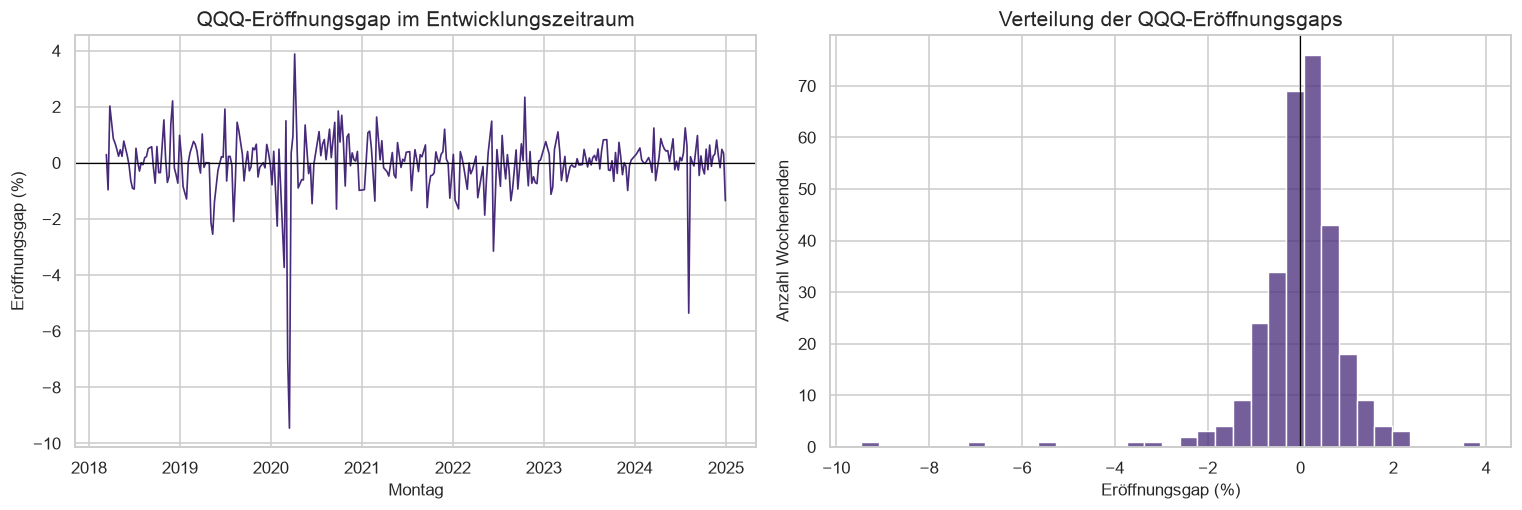

In [11]:
# Restrict every exploratory result to the development period
development_data = modeling_data[
    modeling_data["monday_date"] < HOLDOUT_START
].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].plot(
    development_data["monday_date"],
    development_data["qqq_gap_percent"],
    color=COLORS["qqq"],
    linewidth=1.1,
)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("QQQ-Eröffnungsgap im Entwicklungszeitraum")
axes[0].set_xlabel("Montag")
axes[0].set_ylabel("Eröffnungsgap (%)")

sns.histplot(
    data=development_data,
    x="qqq_gap_percent",
    bins=35,
    color=COLORS["qqq"],
    ax=axes[1],
)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Verteilung der QQQ-Eröffnungsgaps")
axes[1].set_xlabel("Eröffnungsgap (%)")
axes[1].set_ylabel("Anzahl Wochenenden")

fig.tight_layout()
plt.show()

In [12]:
# Quantify only patterns visible in the development sample
mean_gap = development_data["qqq_gap_percent"].mean()
median_gap = development_data["qqq_gap_percent"].median()
positive_share = development_data["qqq_gap_direction"].mean()
absolute_gap_95 = development_data["qqq_gap_percent"].abs().quantile(0.95)

display(
    Markdown(
        f'''
### Interpretation

Der mittlere QQQ-Eröffnungsgap beträgt **{mean_gap:.3f}%**, der Median
**{median_gap:.3f}%**. In **{positive_share:.1%}** der
Entwicklungswochen eröffnet QQQ höher als am Freitagsschluss. 95% der
absoluten Gaps liegen unter **{absolute_gap_95:.2f}%**. Die Zeitreihe
zeigt einzelne grosse Ausschläge; deshalb ist eine robuste einfache
Fehlermetrik wie MAE für den späteren Modellvergleich sinnvoll.
        '''
    )
)


### Interpretation

Der mittlere QQQ-Eröffnungsgap beträgt **-0.027%**, der Median
**0.075%**. In **55.9%** der
Entwicklungswochen eröffnet QQQ höher als am Freitagsschluss. 95% der
absoluten Gaps liegen unter **1.83%**. Die Zeitreihe
zeigt einzelne grosse Ausschläge; deshalb ist eine robuste einfache
Fehlermetrik wie MAE für den späteren Modellvergleich sinnvoll.
        

### 7.2 Bitcoin-Wochenendrendite und QQQ-Gap

Wir prüfen visuell, ob positive beziehungsweise negative
Bitcoin-Wochenenden mit dem QQQ-Eröffnungsgap zusammenhängen. Die Null-
Linien teilen die Darstellung in vier Richtungsfälle.

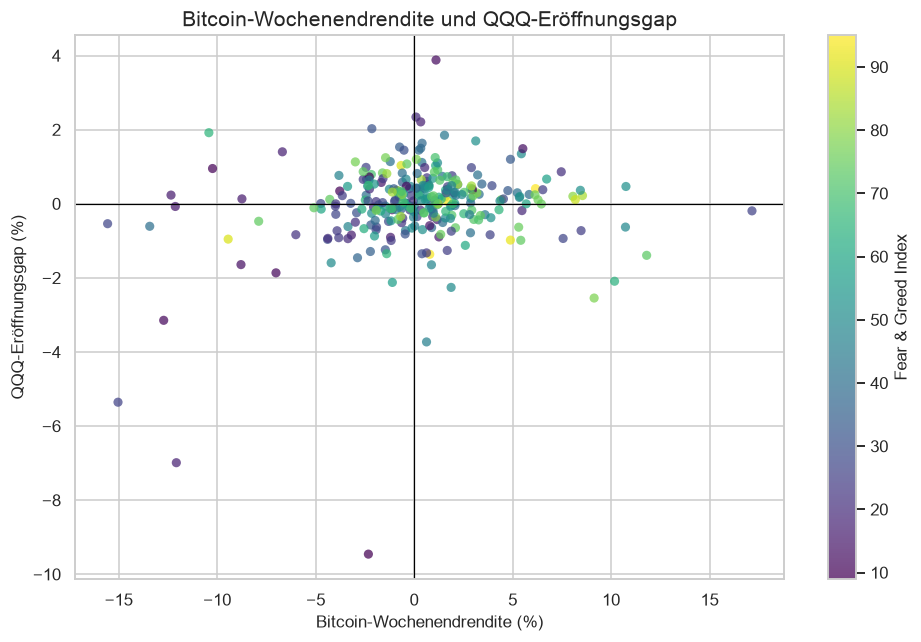

In [13]:
# Plot the direct relationship without fitting a predictive model yet
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    100 * development_data["btc_weekend_return"],
    development_data["qqq_gap_percent"],
    c=development_data["fear_greed"],
    cmap="viridis",
    alpha=0.72,
    edgecolor="none",
)
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Bitcoin-Wochenendrendite und QQQ-Eröffnungsgap")
plt.xlabel("Bitcoin-Wochenendrendite (%)")
plt.ylabel("QQQ-Eröffnungsgap (%)")
colorbar = plt.colorbar(scatter)
colorbar.set_label("Fear & Greed Index")
plt.tight_layout()
plt.show()

In [14]:
# Compare correlations for all, negative and positive Bitcoin weekends
overall_correlation = development_data[
    ["btc_weekend_return", "qqq_gap_log_return"]
].corr().iloc[0, 1]
negative_weekends = development_data[development_data["btc_weekend_return"] < 0]
positive_weekends = development_data[development_data["btc_weekend_return"] >= 0]
negative_correlation = negative_weekends[
    ["btc_weekend_return", "qqq_gap_log_return"]
].corr().iloc[0, 1]
positive_correlation = positive_weekends[
    ["btc_weekend_return", "qqq_gap_log_return"]
].corr().iloc[0, 1]

correlation_by_sign = pd.DataFrame(
    {
        "Teilmenge": ["Alle", "BTC negativ", "BTC positiv"],
        "Beobachtungen": [
            len(development_data),
            len(negative_weekends),
            len(positive_weekends),
        ],
        "Korrelation": [
            overall_correlation,
            negative_correlation,
            positive_correlation,
        ],
    }
)
display(correlation_by_sign.round(3))

display(
    Markdown(
        f'''
### Interpretation

Im gesamten Entwicklungszeitraum beträgt die lineare Korrelation
**{overall_correlation:.3f}**. Für negative Bitcoin-Wochenenden liegt sie
bei **{negative_correlation:.3f}**, für positive Wochenenden bei
**{positive_correlation:.3f}**. Diese deskriptiven Werte können auf eine
asymmetrische Beziehung hindeuten, belegen aber noch keine stabile
Out-of-Sample-Prognose. Der spätere Feature-Vergleich muss zeigen, ob der
Zusammenhang gegenüber QQQ-, Sentiment- und Makroinformationen einen
echten Zusatznutzen besitzt.
        '''
    )
)

,Teilmenge,Beobachtungen,Korrelation
0,Alle,304,0.184
1,BTC negativ,137,0.323
2,BTC positiv,167,-0.176



### Interpretation

Im gesamten Entwicklungszeitraum beträgt die lineare Korrelation
**0.184**. Für negative Bitcoin-Wochenenden liegt sie
bei **0.323**, für positive Wochenenden bei
**-0.176**. Diese deskriptiven Werte können auf eine
asymmetrische Beziehung hindeuten, belegen aber noch keine stabile
Out-of-Sample-Prognose. Der spätere Feature-Vergleich muss zeigen, ob der
Zusammenhang gegenüber QQQ-, Sentiment- und Makroinformationen einen
echten Zusatznutzen besitzt.
        

### 7.3 Kompakte Korrelationsübersicht

Wir vergleichen das Ziel mit wenigen vorab definierten Einflussgrössen.
Die Übersicht dient der Plausibilitätsprüfung und nicht der automatischen
Feature-Auswahl.

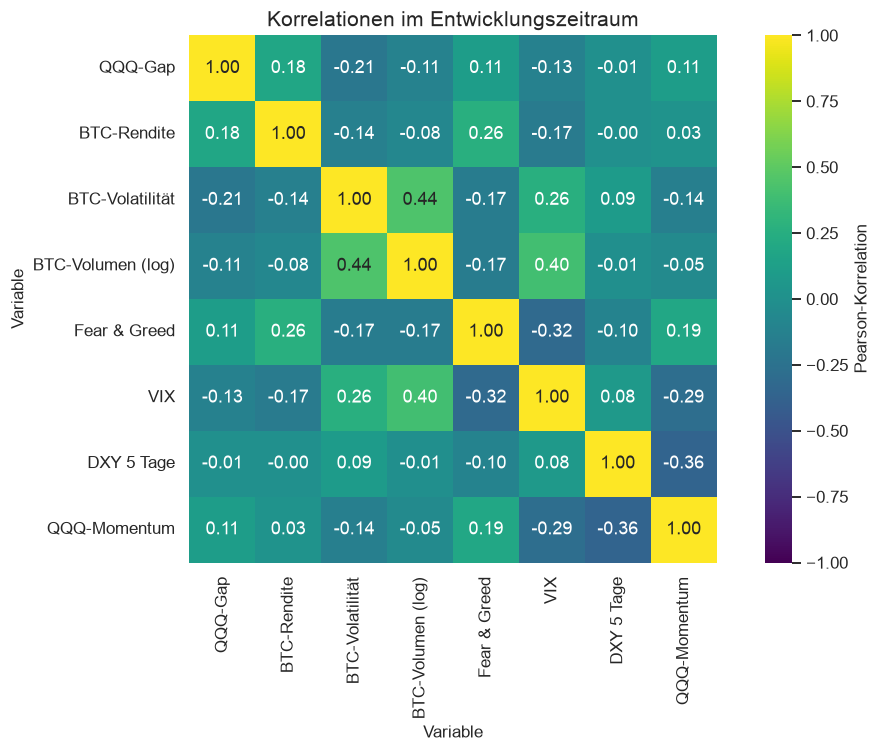

In [15]:
# Keep the heatmap focused on the research question
correlation_columns = [
    "qqq_gap_log_return",
    "btc_weekend_return",
    "btc_weekend_rv",
    "btc_weekend_log_volume",
    "fear_greed",
    "vix_close",
    "dxy_change_5d",
    "qqq_momentum_5d",
]
correlation_labels = {
    "qqq_gap_log_return": "QQQ-Gap",
    "btc_weekend_return": "BTC-Rendite",
    "btc_weekend_rv": "BTC-Volatilität",
    "btc_weekend_log_volume": "BTC-Volumen (log)",
    "fear_greed": "Fear & Greed",
    "vix_close": "VIX",
    "dxy_change_5d": "DXY 5 Tage",
    "qqq_momentum_5d": "QQQ-Momentum",
}
correlation_matrix = development_data[correlation_columns].corr().rename(
    index=correlation_labels, columns=correlation_labels
)

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    cmap="viridis",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    cbar_kws={"label": "Pearson-Korrelation"},
)
plt.title("Korrelationen im Entwicklungszeitraum")
plt.xlabel("Variable")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

In [16]:
# Rank target correlations for a concise evidence-based interpretation
target_correlations = (
    development_data[correlation_columns]
    .corr()["qqq_gap_log_return"]
    .drop("qqq_gap_log_return")
    .sort_values(key=lambda values: values.abs(), ascending=False)
)
strongest_feature = target_correlations.index[0]
strongest_value = target_correlations.iloc[0]

display(target_correlations.rename("Korrelation mit QQQ-Gap").round(3).to_frame())
display(
    Markdown(
        f'''
### Interpretation

Die stärkste absolute lineare Zielkorrelation in dieser bewusst kleinen
Auswahl besitzt **`{strongest_feature}`** mit **{strongest_value:.3f}**.
Die Grössenordnung bleibt eine In-Sample-Beschreibung. Stark korrelierte
Features können redundant sein, und schwach korrelierte Features können
in nichtlinearen Modellen dennoch gemeinsam nützlich werden. Wir behalten
deshalb die vorab definierten Kontroll- und Bitcoin-Feature-Sets bei.
        '''
    )
)

,Korrelation mit QQQ-Gap
btc_weekend_rv,-0.208
btc_weekend_return,0.184
vix_close,-0.132
btc_weekend_log_volume,-0.112
qqq_momentum_5d,0.107
fear_greed,0.106
dxy_change_5d,-0.005



### Interpretation

Die stärkste absolute lineare Zielkorrelation in dieser bewusst kleinen
Auswahl besitzt **`btc_weekend_rv`** mit **-0.208**.
Die Grössenordnung bleibt eine In-Sample-Beschreibung. Stark korrelierte
Features können redundant sein, und schwach korrelierte Features können
in nichtlinearen Modellen dennoch gemeinsam nützlich werden. Wir behalten
deshalb die vorab definierten Kontroll- und Bitcoin-Feature-Sets bei.
        

## 8. Expanding-window-Backtesting und Baselines

### Erklärung

Wir verwenden keine zufällige Aufteilung. Für jedes Validierungsjahr
trainieren wir zunächst auf allen früheren Beobachtungen. Innerhalb
des Jahres wächst das Trainingsfenster Woche für Woche weiter:

```text
Fold 1: Vergangenheit bis 2020 -> Validierung 2021
Fold 2: Vergangenheit bis 2021 -> Validierung 2022
Fold 3: Vergangenheit bis 2022 -> Validierung 2023
Fold 4: Vergangenheit bis 2023 -> Validierung 2024
Finaler Holdout: ab 2025, noch nicht verwendet
```

Baselines und XGBoost werden vor jedem Prognosemontag mit allen bis
dahin beobachteten Zielwerten aktualisiert. SARIMAX schätzt seine
Parameter einmal vor jedem Validierungsjahr und aktualisiert danach
wöchentlich nur den Zeitreihenzustand mit dem neu beobachteten Gap.
Diese unterschiedliche Refit-Frequenz wird in den Modellabschnitten
transparent ausgewiesen.

Am Sonntag vor dem Ziel-Montag sind sämtliche früheren
Montag-Eröffnungsgaps bereits bekannt. Die Zielvariable umfasst nur
einen Zeitpunkt und überlappt nicht mit späteren Zielwochen. Deshalb
ist hier kein zusätzlicher Purge-Abstand wie bei der früheren
siebentägigen Volatilitätsvariable erforderlich.

Wir verwenden zwei leicht nachvollziehbare Baselines:

1. **Null-Gap:** QQQ eröffnet auf dem Freitags-Schlusskurs.
2. **Historischer Mittelwert:** Wir prognostizieren den Mittelwert
   aller bis zum jeweiligen Sonntag bekannten früheren Gaps.

### 8.1 Metriken

Wir verwenden nur die zwei im Konzept festgelegten Hauptmetriken.

Der Mean Absolute Error wird in Prozentpunkten des Eröffnungsgaps
berechnet:

$$
MAE = \frac{1}{n}\sum_{t=1}^{n}|y_t-\hat y_t|.
$$

Die Richtungsgenauigkeit misst den Anteil korrekter Vorzeichen:

$$
Directional\ Accuracy
= \frac{1}{n}\sum_{t=1}^{n}
\mathbb{1}\left(
\mathbb{1}(y_t>0)=\mathbb{1}(\hat y_t>0)
\right).
$$

Eine Null-Prognose wird mit dieser klaren Regel als nicht positiv
eingestuft. Ihre Richtungsgenauigkeit entspricht deshalb dem Anteil
nicht positiver tatsächlicher Gaps.

In [17]:
def mean_absolute_error(y_true, y_pred):
    # Calculate MAE explicitly so the metric remains transparent
    actual = np.asarray(y_true, dtype=float)
    predicted = np.asarray(y_pred, dtype=float)
    assert actual.shape == predicted.shape
    assert np.isfinite(actual).all() and np.isfinite(predicted).all()
    return np.mean(np.abs(actual - predicted))


def directional_accuracy(y_true, y_pred):
    # Treat exactly zero as non-positive in both arrays
    actual = np.asarray(y_true, dtype=float)
    predicted = np.asarray(y_pred, dtype=float)
    assert actual.shape == predicted.shape
    assert np.isfinite(actual).all() and np.isfinite(predicted).all()
    return np.mean((actual > 0) == (predicted > 0))


# Verify both metric implementations with deterministic examples
metric_test_actual = np.array([-1.0, 2.0])
metric_test_table = pd.DataFrame(
    {
        "Test": ["Perfekte Prognose", "Null-Prognose"],
        "Erwarteter MAE": [0.0, 1.5],
        "Berechneter MAE": [
            mean_absolute_error(metric_test_actual, metric_test_actual),
            mean_absolute_error(metric_test_actual, np.zeros(2)),
        ],
        "Erwartete Richtungsgenauigkeit": [1.0, 0.5],
        "Berechnete Richtungsgenauigkeit": [
            directional_accuracy(metric_test_actual, metric_test_actual),
            directional_accuracy(metric_test_actual, np.zeros(2)),
        ],
    }
)
assert np.allclose(
    metric_test_table["Erwarteter MAE"],
    metric_test_table["Berechneter MAE"],
)
assert np.allclose(
    metric_test_table["Erwartete Richtungsgenauigkeit"],
    metric_test_table["Berechnete Richtungsgenauigkeit"],
)
display(metric_test_table)

,Test,Erwarteter MAE,Berechneter MAE,Erwartete Richtungsgenauigkeit,Berechnete Richtungsgenauigkeit
0,Perfekte Prognose,0.0,0.0,1.0,1.0
1,Null-Prognose,1.5,1.5,0.5,0.5


### Interpretation

Die kleinen deterministischen Tests bestätigen, dass beide
Metrikfunktionen die erwarteten Werte liefern. Wir berechnen die
Funktionen sichtbar im Notebook und vermeiden dadurch versteckte
Voreinstellungen externer Scoring-Funktionen.

### 8.2 Walk-forward-Prognosen

Für jeden Ziel-Montag verwenden wir nur Zeilen mit einem früheren
`monday_date` als Trainingsdaten. Der historische Mittelwert wird
dadurch nach jeder neu beobachteten Woche aktualisiert. Beide
Baselines prognostizieren exakt dieselben Validierungsdaten.

In [18]:
# Keep the final holdout outside every development forecast
development_backtest_data = modeling_data[
    modeling_data["monday_date"] < HOLDOUT_START
].copy()
assert set(VALIDATION_YEARS) == {2021, 2022, 2023, 2024}

baseline_rows = []

for validation_year in VALIDATION_YEARS:
    validation_rows = development_backtest_data[
        development_backtest_data["monday_date"].dt.year == validation_year
    ]
    assert not validation_rows.empty, f"Keine Daten für Fold {validation_year}"

    for validation_row in validation_rows.itertuples(index=False):
        forecast_origin = validation_row.monday_date

        # Expand the training set using only previously observed targets
        training_rows = development_backtest_data[
            development_backtest_data["monday_date"] < forecast_origin
        ]
        assert not training_rows.empty
        assert training_rows["monday_date"].max() < forecast_origin

        historical_mean_prediction = training_rows[
            TARGET_COLUMN
        ].mean()

        for model_name, prediction in [
            ("Null-Gap", 0.0),
            ("Historischer Mittelwert", historical_mean_prediction),
        ]:
            baseline_rows.append(
                {
                    "fold": validation_year,
                    "forecast_date": forecast_origin,
                    "train_start": training_rows["monday_date"].min(),
                    "train_end": training_rows["monday_date"].max(),
                    "train_size": len(training_rows),
                    "model": model_name,
                    "actual_log_gap": validation_row.qqq_gap_log_return,
                    "predicted_log_gap": prediction,
                    "actual_gap_percent": validation_row.qqq_gap_percent,
                    "predicted_gap_percent": 100 * np.expm1(prediction),
                }
            )

baseline_predictions = pd.DataFrame(baseline_rows).sort_values(
    ["forecast_date", "model"]
)

# Validate the shared sample and all temporal boundaries
expected_forecast_dates = development_backtest_data.loc[
    development_backtest_data["monday_date"].dt.year.isin(VALIDATION_YEARS),
    "monday_date",
]
dates_per_model = baseline_predictions.groupby("model")[
    "forecast_date"
].apply(list)
assert all(
    model_dates == expected_forecast_dates.tolist()
    for model_dates in dates_per_model
)
assert (
    baseline_predictions["train_end"]
    < baseline_predictions["forecast_date"]
).all()
assert (baseline_predictions["forecast_date"] < HOLDOUT_START).all()
assert baseline_predictions[
    ["actual_gap_percent", "predicted_gap_percent"]
].notna().all().all()

# Persist a compact audit trail for later model comparisons
baseline_output_path = (
    PROCESSED_DATA_DIR / "btc_weekend_qqq_baseline_backtest.csv"
)
baseline_predictions.to_csv(baseline_output_path, index=False)

fold_overview = (
    baseline_predictions[
        baseline_predictions["model"] == "Null-Gap"
    ]
    .groupby("fold", as_index=False)
    .agg(
        Trainingsbeginn=("train_start", "min"),
        Erstes_Trainingsende=("train_end", "min"),
        Letztes_Trainingsende=("train_end", "max"),
        Minimale_Trainingsgrösse=("train_size", "min"),
        Maximale_Trainingsgrösse=("train_size", "max"),
        Validierungsbeginn=("forecast_date", "min"),
        Validierungsende=("forecast_date", "max"),
        Prognosen=("forecast_date", "size"),
    )
)
display(fold_overview)
baseline_preview = baseline_predictions.head(6).copy()
baseline_numeric_columns = baseline_preview.select_dtypes(
    include="number"
).columns
baseline_preview[baseline_numeric_columns] = baseline_preview[
    baseline_numeric_columns
].round(4)
display(baseline_preview)

,fold,Trainingsbeginn,Erstes_Trainingsende,Letztes_Trainingsende,Minimale_Trainingsgrösse,Maximale_Trainingsgrösse,Validierungsbeginn,Validierungsende,Prognosen
0,2021,2018-03-12,2020-12-21,2021-12-13,127,168,2021-01-11,2021-12-20,42
1,2022,2018-03-12,2021-12-20,2022-12-12,169,212,2022-01-03,2022-12-19,44
2,2023,2018-03-12,2022-12-19,2023-12-11,213,256,2023-01-09,2023-12-18,44
3,2024,2018-03-12,2023-12-18,2024-12-23,257,303,2024-01-08,2024-12-30,47


,fold,forecast_date,train_start,train_end,train_size,model,actual_log_gap,predicted_log_gap,actual_gap_percent,predicted_gap_percent
1,2021,2021-01-11,2018-03-12,2020-12-21,127,Historischer Mittelwert,-0.0096,-0.0003,-0.9560,-0.0266
0,2021,2021-01-11,2018-03-12,2020-12-21,127,Null-Gap,-0.0096,0.0000,-0.9560,0.0000
3,2021,2021-01-25,2018-03-12,2021-01-11,128,Historischer Mittelwert,0.0107,-0.0003,1.0725,-0.0339
2,2021,2021-01-25,2018-03-12,2021-01-11,128,Null-Gap,0.0107,0.0000,1.0725,0.0000
5,2021,2021-02-01,2018-03-12,2021-01-25,129,Historischer Mittelwert,0.0112,-0.0003,1.1286,-0.0254
4,2021,2021-02-01,2018-03-12,2021-01-25,129,Null-Gap,0.0112,0.0000,1.1286,0.0000


In [19]:
# Describe the executed fold handoff without touching the holdout
forecast_count = baseline_predictions["forecast_date"].nunique()
minimum_train_size = baseline_predictions["train_size"].min()
maximum_train_size = baseline_predictions["train_size"].max()
first_forecast = baseline_predictions["forecast_date"].min().date()
last_forecast = baseline_predictions["forecast_date"].max().date()

display(
    Markdown(
        f'''
### Interpretation

Das Backtesting erzeugt für jede Baseline **{forecast_count}
Prognosen** vom **{first_forecast}** bis zum **{last_forecast}**.
Das Expanding Window wächst dabei von **{minimum_train_size}** auf
**{maximum_train_size} Trainingsbeobachtungen**. Jede Prognose besitzt
ein strikt früheres Trainingsende; Daten ab 2025 kommen weder im
Training noch in der Validierung vor.
        '''
    )
)


### Interpretation

Das Backtesting erzeugt für jede Baseline **177
Prognosen** vom **2021-01-11** bis zum **2024-12-30**.
Das Expanding Window wächst dabei von **127** auf
**303 Trainingsbeobachtungen**. Jede Prognose besitzt
ein strikt früheres Trainingsende; Daten ab 2025 kommen weder im
Training noch in der Validierung vor.
        

### 8.3 Ergebnisse der Baselines

Wir berechnen die gepoolten Kennzahlen auf den identischen
Prognosedaten beider Modelle. Zusätzlich zeigen wir die Werte je
Validierungsjahr, damit ein einzelnes Marktjahr das Gesamtergebnis
nicht unbemerkt bestimmt.

In [20]:
def summarize_model_metrics(frame):
    # Aggregate both simple metrics on one prediction sample
    return pd.Series(
        {
            "MAE (Prozentpunkte)": mean_absolute_error(
                frame["actual_gap_percent"],
                frame["predicted_gap_percent"],
            ),
            "Richtungsgenauigkeit": directional_accuracy(
                frame["actual_log_gap"],
                frame["predicted_log_gap"],
            ),
            "Prognosen": len(frame),
        }
    )


baseline_metric_rows = []
for model_name, model_frame in baseline_predictions.groupby("model"):
    metrics = summarize_model_metrics(model_frame)
    baseline_metric_rows.append(
        {
            "Modell": model_name,
            **metrics.to_dict(),
        }
    )
baseline_metrics = pd.DataFrame(baseline_metric_rows).sort_values(
    "MAE (Prozentpunkte)"
)

fold_metric_rows = []
for (fold, model_name), fold_frame in baseline_predictions.groupby(
    ["fold", "model"]
):
    metrics = summarize_model_metrics(fold_frame)
    fold_metric_rows.append(
        {
            "Validierungsjahr": fold,
            "Modell": model_name,
            **metrics.to_dict(),
        }
    )
baseline_fold_metrics = pd.DataFrame(fold_metric_rows).sort_values(
    ["Validierungsjahr", "MAE (Prozentpunkte)"]
)

display(baseline_metrics.round(4))
display(baseline_fold_metrics.round(4))

,Modell,MAE (Prozentpunkte),Richtungsgenauigkeit,Prognosen
1,Null-Gap,0.5225,0.4576,177.0
0,Historischer Mittelwert,0.5276,0.4576,177.0


,Validierungsjahr,Modell,MAE (Prozentpunkte),Richtungsgenauigkeit,Prognosen
1,2021,Null-Gap,0.5346,0.4524,42.0
0,2021,Historischer Mittelwert,0.5384,0.4524,42.0
2,2022,Historischer Mittelwert,0.6729,0.5909,44.0
3,2022,Null-Gap,0.6754,0.5909,44.0
5,2023,Null-Gap,0.3743,0.5000,44.0
4,2023,Historischer Mittelwert,0.3749,0.5000,44.0
7,2024,Null-Gap,0.5071,0.2979,47.0
6,2024,Historischer Mittelwert,0.5250,0.2979,47.0


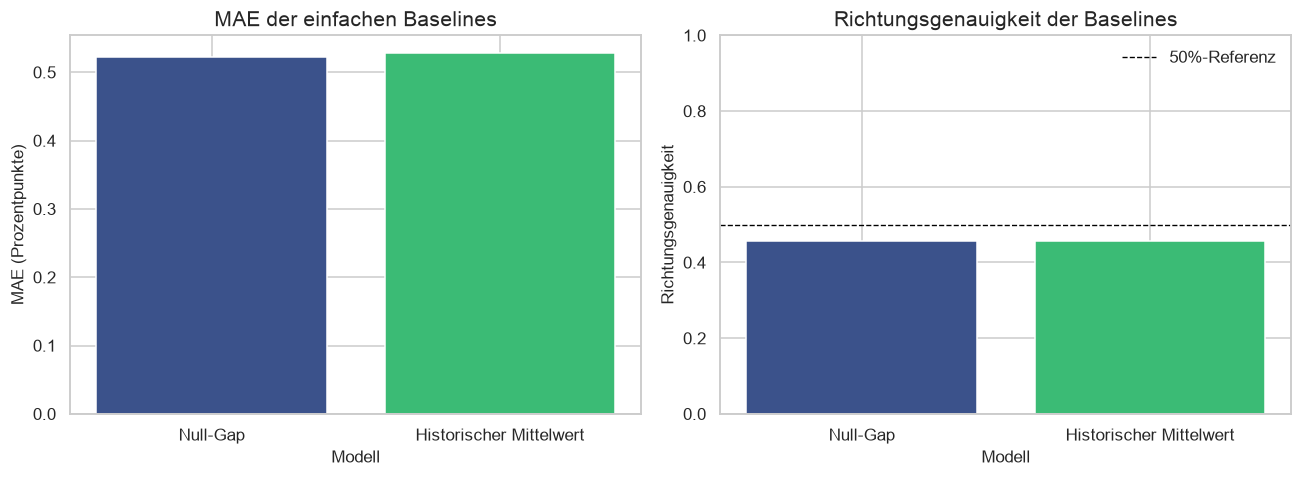

In [21]:
# Plot both agreed metrics without combining incompatible scales
model_order = ["Null-Gap", "Historischer Mittelwert"]
model_colors = [VIRIDIS(0.25), VIRIDIS(0.68)]
plot_metrics = baseline_metrics.set_index("Modell").loc[model_order]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(
    model_order,
    plot_metrics["MAE (Prozentpunkte)"],
    color=model_colors,
)
axes[0].set_title("MAE der einfachen Baselines")
axes[0].set_xlabel("Modell")
axes[0].set_ylabel("MAE (Prozentpunkte)")
axes[0].set_ylim(bottom=0)

axes[1].bar(
    model_order,
    plot_metrics["Richtungsgenauigkeit"],
    color=model_colors,
)
axes[1].axhline(
    0.5,
    color="black",
    linewidth=0.9,
    linestyle="--",
    label="50%-Referenz",
)
axes[1].set_title("Richtungsgenauigkeit der Baselines")
axes[1].set_xlabel("Modell")
axes[1].set_ylabel("Richtungsgenauigkeit")
axes[1].set_ylim(0, 1)
axes[1].legend()

fig.tight_layout()
plt.show()

In [22]:
# Derive the written result only from executed backtest metrics
best_mae_row = baseline_metrics.iloc[0]
null_mae = baseline_metrics.loc[
    baseline_metrics["Modell"] == "Null-Gap", "MAE (Prozentpunkte)"
].iloc[0]
mean_mae = baseline_metrics.loc[
    baseline_metrics["Modell"] == "Historischer Mittelwert",
    "MAE (Prozentpunkte)",
].iloc[0]
mae_difference = abs(null_mae - mean_mae)

best_direction_value = baseline_metrics["Richtungsgenauigkeit"].max()
direction_leaders = baseline_metrics.loc[
    np.isclose(
        baseline_metrics["Richtungsgenauigkeit"],
        best_direction_value,
    ),
    "Modell",
].tolist()
if len(direction_leaders) == len(baseline_metrics):
    direction_text = "Beide Baselines"
else:
    direction_text = ", ".join(direction_leaders)
direction_delta_points = 100 * (best_direction_value - 0.5)
direction_position = "über" if direction_delta_points >= 0 else "unter"

fold_mae_wins = (
    baseline_fold_metrics.sort_values("MAE (Prozentpunkte)")
    .groupby("Validierungsjahr")
    .first()["Modell"]
    .value_counts()
    .to_dict()
)
fold_count = baseline_fold_metrics["Validierungsjahr"].nunique()
fold_win_text = ", ".join(
    f"{model_name}: {win_count} von {fold_count} Jahren"
    for model_name, win_count in fold_mae_wins.items()
)

display(
    Markdown(
        f'''
### Interpretation

Die beste einfache Baseline nach MAE ist **{best_mae_row['Modell']}**
mit **{best_mae_row['MAE (Prozentpunkte)']:.3f}
Prozentpunkten**. Die Null-Gap-Baseline erreicht **{null_mae:.3f}**,
der historische Mittelwert **{mean_mae:.3f} Prozentpunkte**. Der
Unterschied von **{mae_difference:.3f} Prozentpunkten** ist klein,
der Null-Gap bleibt aber der strengere Mindestvergleich.

**{direction_text}** erreichen eine Richtungsgenauigkeit von
**{best_direction_value:.1%}**. Das liegt
**{abs(direction_delta_points):.1f} Prozentpunkte {direction_position}
der 50%-Referenz**. Die jährlichen MAE-Siege verteilen sich auf
**{fold_win_text}**.

Damit erhalten die folgenden Modelle zwei klare Mindestanforderungen:
Sie sollen den gepoolten Null-Gap-MAE unterschreiten und ihre Leistung
nicht nur in einem einzelnen Validierungsjahr erzielen. Die
Richtungswerte der Baselines sind vor allem Referenzwerte, weil beide
Modelle nur sehr kleine oder konstante Gaps prognostizieren.
        '''
    )
)


### Interpretation

Die beste einfache Baseline nach MAE ist **Null-Gap**
mit **0.522
Prozentpunkten**. Die Null-Gap-Baseline erreicht **0.522**,
der historische Mittelwert **0.528 Prozentpunkte**. Der
Unterschied von **0.005 Prozentpunkten** ist klein,
der Null-Gap bleibt aber der strengere Mindestvergleich.

**Beide Baselines** erreichen eine Richtungsgenauigkeit von
**45.8%**. Das liegt
**4.2 Prozentpunkte unter
der 50%-Referenz**. Die jährlichen MAE-Siege verteilen sich auf
**Null-Gap: 3 von 4 Jahren, Historischer Mittelwert: 1 von 4 Jahren**.

Damit erhalten die folgenden Modelle zwei klare Mindestanforderungen:
Sie sollen den gepoolten Null-Gap-MAE unterschreiten und ihre Leistung
nicht nur in einem einzelnen Validierungsjahr erzielen. Die
Richtungswerte der Baselines sind vor allem Referenzwerte, weil beide
Modelle nur sehr kleine oder konstante Gaps prognostizieren.
        

## 9. SARIMAX als traditionelle Zeitreihenmethode

### Erklärung

SARIMAX verbindet eine autoregressive Zeitreihenstruktur mit
externen Einflussgrössen. Wir verwenden bewusst eine kleine
Spezifikation mit einem AR-Term und ohne saisonale Komponente:

$$
y_t = c + \beta^T x_t + \phi_1 y_{t-1} + \varepsilon_t.
$$

Dabei ist $y_t$ der logarithmische QQQ-Eröffnungsgap. Der Vektor
$x_t$ enthält entweder nur die Kontrollvariablen oder zusätzlich die
Bitcoin-Wochenendmerkmale.

Wir vergleichen zwei Varianten:

1. **SARIMAX Kontrolle:** QQQ-Historie, Fear & Greed, VIX und DXY.
2. **SARIMAX + Bitcoin:** dieselben Variablen plus Bitcoin-Rendite,
   -Volatilität, -Range, -Volumen und maximaler Drawdown.

Die Skalierung wird in jedem Fold ausschliesslich auf den
Trainingsdaten geschätzt. Die Modellparameter werden einmal vor dem
jeweiligen Validierungsjahr angepasst. Nach jeder Ein-Schritt-
Prognose aktualisieren wir den internen Zeitreihenzustand mit dem nun
beobachteten tatsächlichen Gap, ohne die Parameter neu zu schätzen.
So bleibt die Berechnung kompakt und entspricht dem realen
wöchentlichen Informationsfluss. Für die Parameterschätzung verwenden
wir den robusten Powell-Optimierer und protokollieren seine Konvergenz.

In [23]:
from sklearn.preprocessing import StandardScaler
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.statespace.sarimax import SARIMAX


SARIMAX_ORDER = (1, 0, 0)
SARIMAX_OPTIMIZER = "powell"
SARIMAX_MAX_ITERATIONS = 300


def fit_and_forecast_sarimax(train_frame, validation_frame, feature_columns):
    # Fit every transformation only on the current training fold
    scaler = StandardScaler()
    train_exog = scaler.fit_transform(train_frame[feature_columns])
    validation_exog = scaler.transform(validation_frame[feature_columns])
    train_target = train_frame[TARGET_COLUMN].to_numpy(dtype=float)

    assert np.isfinite(train_exog).all()
    assert np.isfinite(validation_exog).all()
    assert np.isfinite(train_target).all()

    model = SARIMAX(
        train_target,
        exog=train_exog,
        order=SARIMAX_ORDER,
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False,
    )

    # Record convergence warnings instead of hiding model instability
    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always")
        fitted_result = model.fit(
            disp=False,
            method=SARIMAX_OPTIMIZER,
            maxiter=SARIMAX_MAX_ITERATIONS,
        )

    convergence_warning_count = sum(
        issubclass(item.category, ConvergenceWarning)
        for item in caught_warnings
    )
    converged = bool(fitted_result.mle_retvals.get("converged", False))

    predictions = []
    current_result = fitted_result

    for row_position, validation_row in enumerate(
        validation_frame.itertuples(index=False)
    ):
        # Forecast only the current Monday with its Sunday-known features
        current_exog = validation_exog[row_position : row_position + 1]
        forecast = current_result.forecast(steps=1, exog=current_exog)
        prediction = float(np.asarray(forecast).reshape(-1)[0])
        assert np.isfinite(prediction)
        predictions.append(prediction)

        # Update the state after observing this Monday, without refitting
        actual_target = np.array([validation_row.qqq_gap_log_return])
        current_result = current_result.append(
            endog=actual_target,
            exog=current_exog,
            refit=False,
        )

    diagnostics = {
        "converged": converged,
        "convergence_warnings": convergence_warning_count,
        "aic": float(fitted_result.aic),
        "parameters": int(len(fitted_result.params)),
        "iterations": int(fitted_result.mle_retvals.get("iterations", 0)),
    }
    return np.asarray(predictions), diagnostics

In [24]:
# Forecast the same annual validation folds used by the baselines
sarimax_variants = {
    "SARIMAX Kontrolle": CONTROL_FEATURES,
    "SARIMAX + Bitcoin": FULL_FEATURES,
}
sarimax_prediction_rows = []
sarimax_diagnostic_rows = []

for validation_year in VALIDATION_YEARS:
    train_frame = development_backtest_data[
        development_backtest_data["monday_date"].dt.year
        < validation_year
    ].copy()
    validation_frame = development_backtest_data[
        development_backtest_data["monday_date"].dt.year
        == validation_year
    ].copy()

    assert not train_frame.empty and not validation_frame.empty
    assert train_frame["monday_date"].max() < validation_frame[
        "monday_date"
    ].min()

    for model_name, feature_columns in sarimax_variants.items():
        predictions, diagnostics = fit_and_forecast_sarimax(
            train_frame,
            validation_frame,
            feature_columns,
        )
        assert len(predictions) == len(validation_frame)

        for validation_row, prediction in zip(
            validation_frame.itertuples(index=False),
            predictions,
            strict=True,
        ):
            sarimax_prediction_rows.append(
                {
                    "fold": validation_year,
                    "forecast_date": validation_row.monday_date,
                    "train_start": train_frame["monday_date"].min(),
                    "train_end": train_frame["monday_date"].max(),
                    "train_size": len(train_frame),
                    "model": model_name,
                    "actual_log_gap": validation_row.qqq_gap_log_return,
                    "predicted_log_gap": prediction,
                    "actual_gap_percent": validation_row.qqq_gap_percent,
                    "predicted_gap_percent": 100 * np.expm1(prediction),
                }
            )

        sarimax_diagnostic_rows.append(
            {
                "Validierungsjahr": validation_year,
                "Modell": model_name,
                "Features": len(feature_columns),
                "Trainingszeilen": len(train_frame),
                "Konvergiert": diagnostics["converged"],
                "Konvergenzwarnungen": diagnostics[
                    "convergence_warnings"
                ],
                "Iterationen": diagnostics["iterations"],
                "Parameter": diagnostics["parameters"],
                "AIC": diagnostics["aic"],
            }
        )

sarimax_predictions = pd.DataFrame(sarimax_prediction_rows).sort_values(
    ["forecast_date", "model"]
)
sarimax_diagnostics = pd.DataFrame(sarimax_diagnostic_rows).sort_values(
    ["Validierungsjahr", "Modell"]
)

# Enforce the same temporal and sample contracts as for the baselines
assert (sarimax_predictions["forecast_date"] < HOLDOUT_START).all()
assert (
    sarimax_predictions["train_end"]
    < sarimax_predictions["forecast_date"]
).all()
sarimax_dates_per_model = sarimax_predictions.groupby("model")[
    "forecast_date"
].apply(list)
assert all(
    model_dates == expected_forecast_dates.tolist()
    for model_dates in sarimax_dates_per_model
)
assert sarimax_predictions[
    ["actual_gap_percent", "predicted_gap_percent"]
].notna().all().all()

sarimax_output_path = (
    PROCESSED_DATA_DIR / "btc_weekend_qqq_sarimax_backtest.csv"
)
sarimax_predictions.to_csv(sarimax_output_path, index=False)

display(sarimax_diagnostics.round({"AIC": 2}))
sarimax_preview = sarimax_predictions.head(6).copy()
sarimax_numeric_columns = sarimax_preview.select_dtypes(
    include="number"
).columns
sarimax_preview[sarimax_numeric_columns] = sarimax_preview[
    sarimax_numeric_columns
].round(4)
display(sarimax_preview)

,Validierungsjahr,Modell,Features,Trainingszeilen,Konvergiert,Konvergenzwarnungen,Iterationen,Parameter,AIC
1,2021,SARIMAX + Bitcoin,15,127,True,0,1,18,-700.03
0,2021,SARIMAX Kontrolle,10,127,True,0,3,13,-704.24
3,2022,SARIMAX + Bitcoin,15,169,True,0,1,18,-972.08
2,2022,SARIMAX Kontrolle,10,169,True,0,2,13,-977.21
5,2023,SARIMAX + Bitcoin,15,213,True,0,1,18,-1249.70
4,2023,SARIMAX Kontrolle,10,213,True,0,1,13,-1251.52
7,2024,SARIMAX + Bitcoin,15,257,True,0,1,18,-1554.50
6,2024,SARIMAX Kontrolle,10,257,True,0,1,13,-1554.35


,fold,forecast_date,train_start,train_end,train_size,model,actual_log_gap,predicted_log_gap,actual_gap_percent,predicted_gap_percent
42,2021,2021-01-11,2018-03-12,2020-12-21,127,SARIMAX + Bitcoin,-0.0096,-0.0137,-0.9560,-1.3570
0,2021,2021-01-11,2018-03-12,2020-12-21,127,SARIMAX Kontrolle,-0.0096,-0.0027,-0.9560,-0.2720
43,2021,2021-01-25,2018-03-12,2020-12-21,127,SARIMAX + Bitcoin,0.0107,0.0007,1.0725,0.0725
1,2021,2021-01-25,2018-03-12,2020-12-21,127,SARIMAX Kontrolle,0.0107,0.0006,1.0725,0.0612
44,2021,2021-02-01,2018-03-12,2020-12-21,127,SARIMAX + Bitcoin,0.0112,-0.0042,1.1286,-0.4167
2,2021,2021-02-01,2018-03-12,2020-12-21,127,SARIMAX Kontrolle,0.0112,-0.0014,1.1286,-0.1368


In [25]:
# Explain fit stability from the recorded diagnostics
converged_fits = int(sarimax_diagnostics["Konvergiert"].sum())
total_fits = len(sarimax_diagnostics)
warning_count = int(
    sarimax_diagnostics["Konvergenzwarnungen"].sum()
)
max_iterations_used = int(sarimax_diagnostics["Iterationen"].max())

display(
    Markdown(
        f'''
### Interpretation

**{converged_fits} von {total_fits} SARIMAX-Fits** melden eine
erfolgreiche Optimierung. Die Fits erzeugen insgesamt
**{warning_count} Konvergenzwarnungen**; maximal werden
**{max_iterations_used} Iterationen** benötigt. Die Diagnosetabelle
bleibt sichtbar, damit gute Prognosewerte nicht über ein instabiles Fit-Verhalten
hinwegtäuschen können.

Für jeden Fold endet das Parameterschätzungsfenster vor dem ersten
Validierungs-Montag. Innerhalb des Jahres verwenden wir tatsächliche
Gaps erst nach ihrer jeweiligen Prognose zur Zustandsaktualisierung.
Der Holdout bleibt unberührt.
        '''
    )
)


### Interpretation

**8 von 8 SARIMAX-Fits** melden eine
erfolgreiche Optimierung. Die Fits erzeugen insgesamt
**0 Konvergenzwarnungen**; maximal werden
**3 Iterationen** benötigt. Die Diagnosetabelle
bleibt sichtbar, damit gute Prognosewerte nicht über ein instabiles Fit-Verhalten
hinwegtäuschen können.

Für jeden Fold endet das Parameterschätzungsfenster vor dem ersten
Validierungs-Montag. Innerhalb des Jahres verwenden wir tatsächliche
Gaps erst nach ihrer jeweiligen Prognose zur Zustandsaktualisierung.
Der Holdout bleibt unberührt.
        

### 9.2 Modellvergleich

Wir vergleichen SARIMAX und Baselines auf denselben
Forecast-Daten. Besonders wichtig ist der direkte Vergleich zwischen
`SARIMAX Kontrolle` und `SARIMAX + Bitcoin`: Nur dieser Unterschied
misst den zusätzlichen Wert der Bitcoin-Wochenendmerkmale innerhalb
derselben statistischen Methode.

In [26]:
# Combine all predictions on the one shared development sample
comparison_predictions = pd.concat(
    [baseline_predictions, sarimax_predictions],
    ignore_index=True,
)

comparison_metric_rows = []
for model_name, model_frame in comparison_predictions.groupby("model"):
    metrics = summarize_model_metrics(model_frame)
    comparison_metric_rows.append(
        {
            "Modell": model_name,
            **metrics.to_dict(),
        }
    )
comparison_metrics = pd.DataFrame(comparison_metric_rows).sort_values(
    "MAE (Prozentpunkte)"
)

comparison_fold_rows = []
for (fold, model_name), fold_frame in comparison_predictions.groupby(
    ["fold", "model"]
):
    metrics = summarize_model_metrics(fold_frame)
    comparison_fold_rows.append(
        {
            "Validierungsjahr": fold,
            "Modell": model_name,
            **metrics.to_dict(),
        }
    )
comparison_fold_metrics = pd.DataFrame(comparison_fold_rows).sort_values(
    ["Validierungsjahr", "MAE (Prozentpunkte)"]
)

display(comparison_metrics.round(4))
display(comparison_fold_metrics.round(4))

,Modell,MAE (Prozentpunkte),Richtungsgenauigkeit,Prognosen
1,Null-Gap,0.5225,0.4576,177.0
0,Historischer Mittelwert,0.5276,0.4576,177.0
3,SARIMAX Kontrolle,0.6286,0.4237,177.0
2,SARIMAX + Bitcoin,0.7050,0.5085,177.0


,Validierungsjahr,Modell,MAE (Prozentpunkte),Richtungsgenauigkeit,Prognosen
1,2021,Null-Gap,0.5346,0.4524,42.0
0,2021,Historischer Mittelwert,0.5384,0.4524,42.0
3,2021,SARIMAX Kontrolle,0.6496,0.4048,42.0
2,2021,SARIMAX + Bitcoin,0.7896,0.5238,42.0
4,2022,Historischer Mittelwert,0.6729,0.5909,44.0
5,2022,Null-Gap,0.6754,0.5909,44.0
7,2022,SARIMAX Kontrolle,0.8642,0.4091,44.0
6,2022,SARIMAX + Bitcoin,1.0603,0.3864,44.0
9,2023,Null-Gap,0.3743,0.5000,44.0
8,2023,Historischer Mittelwert,0.3749,0.5000,44.0


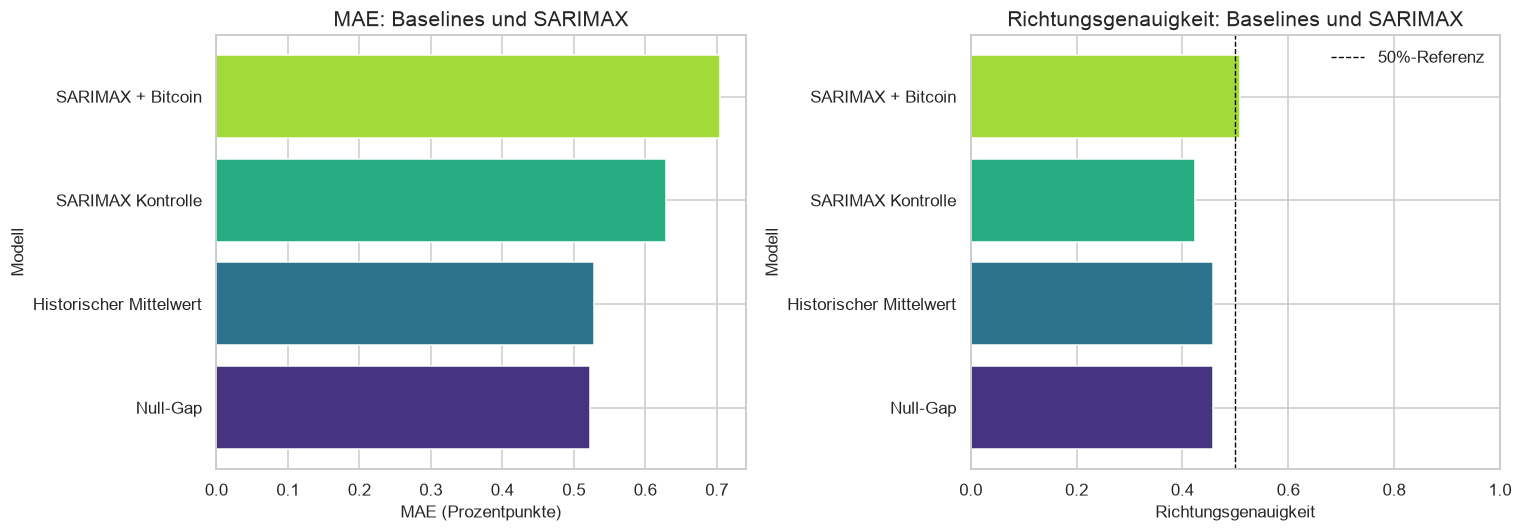

In [27]:
# Plot one compact comparison using stable Viridis-derived colors
comparison_order = [
    "Null-Gap",
    "Historischer Mittelwert",
    "SARIMAX Kontrolle",
    "SARIMAX + Bitcoin",
]
comparison_colors = [
    VIRIDIS(0.15),
    VIRIDIS(0.38),
    VIRIDIS(0.62),
    VIRIDIS(0.86),
]
comparison_plot = comparison_metrics.set_index("Modell").loc[
    comparison_order
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(
    comparison_order,
    comparison_plot["MAE (Prozentpunkte)"],
    color=comparison_colors,
)
axes[0].set_title("MAE: Baselines und SARIMAX")
axes[0].set_xlabel("MAE (Prozentpunkte)")
axes[0].set_ylabel("Modell")
axes[0].set_xlim(left=0)

axes[1].barh(
    comparison_order,
    comparison_plot["Richtungsgenauigkeit"],
    color=comparison_colors,
)
axes[1].axvline(
    0.5,
    color="black",
    linewidth=0.9,
    linestyle="--",
    label="50%-Referenz",
)
axes[1].set_title("Richtungsgenauigkeit: Baselines und SARIMAX")
axes[1].set_xlabel("Richtungsgenauigkeit")
axes[1].set_ylabel("Modell")
axes[1].set_xlim(0, 1)
axes[1].legend()

fig.tight_layout()
plt.show()

In [28]:
# Interpret only the executed shared-sample comparison
best_model_row = comparison_metrics.iloc[0]
control_row = comparison_metrics.loc[
    comparison_metrics["Modell"] == "SARIMAX Kontrolle"
].iloc[0]
bitcoin_row = comparison_metrics.loc[
    comparison_metrics["Modell"] == "SARIMAX + Bitcoin"
].iloc[0]
null_row = comparison_metrics.loc[
    comparison_metrics["Modell"] == "Null-Gap"
].iloc[0]

bitcoin_mae_change = (
    bitcoin_row["MAE (Prozentpunkte)"]
    - control_row["MAE (Prozentpunkte)"]
)
bitcoin_direction_change = (
    bitcoin_row["Richtungsgenauigkeit"]
    - control_row["Richtungsgenauigkeit"]
)
bitcoin_direction_effect = (
    "steigt" if bitcoin_direction_change >= 0 else "sinkt"
)
bitcoin_direction_years_above_reference = int(
    (
        comparison_fold_metrics.loc[
            comparison_fold_metrics["Modell"]
            == "SARIMAX + Bitcoin",
            "Richtungsgenauigkeit",
        ]
        > 0.5
    ).sum()
)
bitcoin_mae_effect = "verbessert" if bitcoin_mae_change < 0 else "verschlechtert"
null_mae_change = (
    bitcoin_row["MAE (Prozentpunkte)"]
    - null_row["MAE (Prozentpunkte)"]
)
null_comparison = "unterbietet" if null_mae_change < 0 else "verfehlt"

sarimax_fold_winners = (
    comparison_fold_metrics[
        comparison_fold_metrics["Modell"].isin(sarimax_variants)
    ]
    .sort_values("MAE (Prozentpunkte)")
    .groupby("Validierungsjahr")
    .first()["Modell"]
    .value_counts()
    .to_dict()
)
fold_win_text = ", ".join(
    f"{model_name}: {win_count} von {len(VALIDATION_YEARS)} Jahren"
    for model_name, win_count in sarimax_fold_winners.items()
)

display(
    Markdown(
        f'''
### Interpretation

Das beste Modell im bisherigen Vergleich ist **{best_model_row['Modell']}**
mit einem MAE von **{best_model_row['MAE (Prozentpunkte)']:.3f}
Prozentpunkten**.

Innerhalb von SARIMAX {bitcoin_mae_effect} die Ergänzung der
Bitcoin-Wochenendmerkmale den MAE um
**{abs(bitcoin_mae_change):.3f} Prozentpunkte**. Die
Richtungsgenauigkeit {bitcoin_direction_effect} dabei um
**{100 * abs(bitcoin_direction_change):.1f} Prozentpunkte** auf
**{bitcoin_row['Richtungsgenauigkeit']:.1%}**. In
**{bitcoin_direction_years_above_reference} von
{len(VALIDATION_YEARS)} Validierungsjahren** liegt sie über 50 %.
`SARIMAX + Bitcoin`
{null_comparison} die Null-Gap-Baseline beim MAE um
**{abs(null_mae_change):.3f} Prozentpunkte**.

Der jährliche direkte SARIMAX-Vergleich ergibt **{fold_win_text}**.
Damit sehen wir einen möglichen Zusatznutzen für die Richtung, aber
keinen Vorteil beim primären numerischen Fehler. Weil SARIMAX auf den
numerischen Gap und nicht direkt auf die Richtung angepasst wird, ist
die Richtungsverbesserung ein sekundäres Signal und kein ausreichender
Nachweis für Prognosekraft.
        '''
    )
)


### Interpretation

Das beste Modell im bisherigen Vergleich ist **Null-Gap**
mit einem MAE von **0.522
Prozentpunkten**.

Innerhalb von SARIMAX verschlechtert die Ergänzung der
Bitcoin-Wochenendmerkmale den MAE um
**0.076 Prozentpunkte**. Die
Richtungsgenauigkeit steigt dabei um
**8.5 Prozentpunkte** auf
**50.8%**. In
**3 von
4 Validierungsjahren** liegt sie über 50 %.
`SARIMAX + Bitcoin`
verfehlt die Null-Gap-Baseline beim MAE um
**0.183 Prozentpunkte**.

Der jährliche direkte SARIMAX-Vergleich ergibt **SARIMAX Kontrolle: 2 von 4 Jahren, SARIMAX + Bitcoin: 2 von 4 Jahren**.
Damit sehen wir einen möglichen Zusatznutzen für die Richtung, aber
keinen Vorteil beim primären numerischen Fehler. Weil SARIMAX auf den
numerischen Gap und nicht direkt auf die Richtung angepasst wird, ist
die Richtungsverbesserung ein sekundäres Signal und kein ausreichender
Nachweis für Prognosekraft.
        

## 10. XGBoost als nichtlineares Machine-Learning-Modell

### Erklärung

XGBoost kombiniert viele kleine Entscheidungsbäume. Jeder neue Baum
korrigiert einen Teil der bisherigen Fehler. Vereinfacht ergibt sich
die Prognose als Summe der einzelnen Bäume:

$$
\hat y_t = \sum_{m=1}^{M}\eta f_m(x_t).
$$

Dabei ist $\eta$ die Lernrate und $f_m$ ein Entscheidungsbaum. Die
Zielfunktion verbindet den Prognosefehler mit einer Regularisierung
der Baumkomplexität:

$$
\mathcal{L}
= \sum_t \left(y_t-\hat y_t\right)^2
+ \sum_{m=1}^{M}\Omega(f_m).
$$

Dadurch kann XGBoost nichtlineare Zusammenhänge und Interaktionen
abbilden, ohne dass wir sie vorab als Formel festlegen müssen.

Wir verwenden bewusst flache Bäume und feste konservative Parameter.
Es gibt keine Hyperparametersuche auf den Validierungsjahren und
keine Nutzung des Holdouts. Für jeden Prognosemontag trainieren wir
neu auf allen früheren Wochen. Eine Skalierung ist für
Entscheidungsbäume nicht erforderlich. XGBoost läuft auf der CPU;
MPS wird später nur für das Foundation Model benötigt.

In [29]:
from xgboost import XGBRegressor


XGBOOST_PARAMETERS = {
    "objective": "reg:squarederror",
    "n_estimators": 250,
    "learning_rate": 0.03,
    "max_depth": 2,
    "min_child_weight": 10,
    "subsample": 0.80,
    "colsample_bytree": 0.80,
    "reg_alpha": 0.0,
    "reg_lambda": 5.0,
    "tree_method": "hist",
    "importance_type": "gain",
    "random_state": RANDOM_SEED,
    "n_jobs": XGBOOST_N_JOBS,
    "verbosity": 0,
}


def fit_xgboost_forecast(train_frame, forecast_frame, feature_columns):
    # Keep the feature order explicit and identical across fit and predict
    train_features = train_frame[feature_columns].astype("float32")
    forecast_features = forecast_frame[feature_columns].astype("float32")
    train_target = train_frame[TARGET_COLUMN].astype("float32")

    # Fail early if a fold contains invalid model input
    assert np.isfinite(train_features.to_numpy()).all()
    assert np.isfinite(forecast_features.to_numpy()).all()
    assert np.isfinite(train_target.to_numpy()).all()

    model = XGBRegressor(**XGBOOST_PARAMETERS)
    model.fit(train_features, train_target, verbose=False)

    prediction = float(model.predict(forecast_features)[0])
    feature_importance = pd.Series(
        model.feature_importances_,
        index=feature_columns,
        dtype=float,
    )
    assert np.isfinite(prediction)
    assert np.isfinite(feature_importance).all()
    return prediction, feature_importance


xgboost_parameter_table = pd.DataFrame(
    {
        "Parameter": list(XGBOOST_PARAMETERS),
        "Wert": [str(value) for value in XGBOOST_PARAMETERS.values()],
    }
)
display(xgboost_parameter_table)

,Parameter,Wert
0,objective,reg:squarederror
1,n_estimators,250
2,learning_rate,0.03
3,max_depth,2
4,min_child_weight,10
5,subsample,0.8
6,colsample_bytree,0.8
7,reg_alpha,0.0
8,reg_lambda,5.0
9,tree_method,hist


In [30]:
# Refit on every forecast date using only already observed targets
xgboost_variants = {
    "XGBoost Kontrolle": CONTROL_FEATURES,
    "XGBoost + Bitcoin": FULL_FEATURES,
}
xgboost_prediction_rows = []
xgboost_importance_rows = []

for validation_year in VALIDATION_YEARS:
    validation_frame = development_backtest_data[
        development_backtest_data["monday_date"].dt.year
        == validation_year
    ].copy()
    assert not validation_frame.empty

    for validation_row_index in validation_frame.index:
        forecast_frame = development_backtest_data.loc[
            [validation_row_index]
        ]
        forecast_date = forecast_frame["monday_date"].iloc[0]

        # Expand through the last Monday observed before this forecast
        train_frame = development_backtest_data[
            development_backtest_data["monday_date"] < forecast_date
        ].copy()
        assert not train_frame.empty
        assert train_frame["monday_date"].max() < forecast_date

        for model_name, feature_columns in xgboost_variants.items():
            prediction, feature_importance = fit_xgboost_forecast(
                train_frame,
                forecast_frame,
                feature_columns,
            )
            actual_log_gap = float(
                forecast_frame[TARGET_COLUMN].iloc[0]
            )
            actual_gap_percent = float(
                forecast_frame["qqq_gap_percent"].iloc[0]
            )

            xgboost_prediction_rows.append(
                {
                    "fold": validation_year,
                    "forecast_date": forecast_date,
                    "train_start": train_frame["monday_date"].min(),
                    "train_end": train_frame["monday_date"].max(),
                    "train_size": len(train_frame),
                    "model": model_name,
                    "actual_log_gap": actual_log_gap,
                    "predicted_log_gap": prediction,
                    "actual_gap_percent": actual_gap_percent,
                    "predicted_gap_percent": 100 * np.expm1(prediction),
                }
            )

            # Keep a transparent record of model usage for every fit
            for feature_name, importance in feature_importance.items():
                xgboost_importance_rows.append(
                    {
                        "fold": validation_year,
                        "forecast_date": forecast_date,
                        "model": model_name,
                        "feature": feature_name,
                        "gain_importance": importance,
                    }
                )

xgboost_predictions = pd.DataFrame(
    xgboost_prediction_rows
).sort_values(["forecast_date", "model"])
xgboost_feature_importance = pd.DataFrame(
    xgboost_importance_rows
).sort_values(["forecast_date", "model", "feature"])

# Enforce the same dates and leakage boundaries as for prior models
xgboost_dates_per_model = xgboost_predictions.groupby("model")[
    "forecast_date"
].apply(list)
assert all(
    model_dates == expected_forecast_dates.tolist()
    for model_dates in xgboost_dates_per_model
)
assert (
    xgboost_predictions["train_end"]
    < xgboost_predictions["forecast_date"]
).all()
assert (xgboost_predictions["forecast_date"] < HOLDOUT_START).all()
assert xgboost_predictions[
    ["actual_gap_percent", "predicted_gap_percent"]
].notna().all().all()
assert np.isfinite(
    xgboost_predictions[
        ["actual_gap_percent", "predicted_gap_percent"]
    ].to_numpy()
).all()

xgboost_output_path = (
    PROCESSED_DATA_DIR / "btc_weekend_qqq_xgboost_backtest.csv"
)
xgboost_importance_path = (
    PROCESSED_DATA_DIR
    / "btc_weekend_qqq_xgboost_feature_importance.csv"
)
xgboost_predictions.to_csv(xgboost_output_path, index=False)
xgboost_feature_importance.to_csv(
    xgboost_importance_path,
    index=False,
)

xgboost_preview = xgboost_predictions.head(6).copy()
xgboost_numeric_columns = xgboost_preview.select_dtypes(
    include="number"
).columns
xgboost_preview[xgboost_numeric_columns] = xgboost_preview[
    xgboost_numeric_columns
].round(4)
display(xgboost_preview)

,fold,forecast_date,train_start,train_end,train_size,model,actual_log_gap,predicted_log_gap,actual_gap_percent,predicted_gap_percent
1,2021,2021-01-11,2018-03-12,2020-12-21,127,XGBoost + Bitcoin,-0.0096,-0.0044,-0.9560,-0.4396
0,2021,2021-01-11,2018-03-12,2020-12-21,127,XGBoost Kontrolle,-0.0096,0.0028,-0.9560,0.2808
3,2021,2021-01-25,2018-03-12,2021-01-11,128,XGBoost + Bitcoin,0.0107,0.0095,1.0725,0.9577
2,2021,2021-01-25,2018-03-12,2021-01-11,128,XGBoost Kontrolle,0.0107,0.0045,1.0725,0.4489
5,2021,2021-02-01,2018-03-12,2021-01-25,129,XGBoost + Bitcoin,0.0112,-0.0003,1.1286,-0.0314
4,2021,2021-02-01,2018-03-12,2021-01-25,129,XGBoost Kontrolle,0.0112,-0.0068,1.1286,-0.6764


In [31]:
# Confirm the actual expanding-window handoff from the predictions
xgboost_forecast_count = xgboost_predictions[
    "forecast_date"
].nunique()
xgboost_minimum_train_size = int(
    xgboost_predictions["train_size"].min()
)
xgboost_maximum_train_size = int(
    xgboost_predictions["train_size"].max()
)

display(
    Markdown(
        f'''
### Interpretation

Beide XGBoost-Varianten erzeugen Prognosen für dieselben
**{xgboost_forecast_count} Montage** wie die bisherigen Modelle.
Das Trainingsfenster wächst von **{xgboost_minimum_train_size}** auf
**{xgboost_maximum_train_size} Wochenbeobachtungen**. Vor jedem Fit
endet das Training strikt vor dem prognostizierten Montag. Der
Holdout ab 2025 bleibt vollständig unberührt.
        '''
    )
)


### Interpretation

Beide XGBoost-Varianten erzeugen Prognosen für dieselben
**177 Montage** wie die bisherigen Modelle.
Das Trainingsfenster wächst von **127** auf
**303 Wochenbeobachtungen**. Vor jedem Fit
endet das Training strikt vor dem prognostizierten Montag. Der
Holdout ab 2025 bleibt vollständig unberührt.
        

### 10.2 Modellvergleich

Wir bewerten XGBoost auf denselben Prognoseterminen und mit denselben
Metriken wie Baselines und SARIMAX. Der direkte Vergleich zwischen
`XGBoost Kontrolle` und `XGBoost + Bitcoin` isoliert den zusätzlichen
Beitrag der Bitcoin-Wochenendmerkmale innerhalb derselben Methode.

In [32]:
# Rebuild one shared comparison table for all implemented models
all_development_predictions = pd.concat(
    [
        baseline_predictions,
        sarimax_predictions,
        xgboost_predictions,
    ],
    ignore_index=True,
)

all_model_metric_rows = []
for model_name, model_frame in all_development_predictions.groupby(
    "model"
):
    metrics = summarize_model_metrics(model_frame)
    all_model_metric_rows.append(
        {
            "Modell": model_name,
            **metrics.to_dict(),
        }
    )
all_model_metrics = pd.DataFrame(
    all_model_metric_rows
).sort_values("MAE (Prozentpunkte)")

all_model_fold_rows = []
for (fold, model_name), fold_frame in (
    all_development_predictions.groupby(["fold", "model"])
):
    metrics = summarize_model_metrics(fold_frame)
    all_model_fold_rows.append(
        {
            "Validierungsjahr": fold,
            "Modell": model_name,
            **metrics.to_dict(),
        }
    )
all_model_fold_metrics = pd.DataFrame(
    all_model_fold_rows
).sort_values(["Validierungsjahr", "MAE (Prozentpunkte)"])

xgboost_fold_metrics = all_model_fold_metrics[
    all_model_fold_metrics["Modell"].isin(xgboost_variants)
]

display(all_model_metrics.round(4))
display(xgboost_fold_metrics.round(4))

,Modell,MAE (Prozentpunkte),Richtungsgenauigkeit,Prognosen
1,Null-Gap,0.5225,0.4576,177.0
0,Historischer Mittelwert,0.5276,0.4576,177.0
4,XGBoost + Bitcoin,0.5494,0.5085,177.0
5,XGBoost Kontrolle,0.6030,0.4859,177.0
3,SARIMAX Kontrolle,0.6286,0.4237,177.0
2,SARIMAX + Bitcoin,0.7050,0.5085,177.0


,Validierungsjahr,Modell,MAE (Prozentpunkte),Richtungsgenauigkeit,Prognosen
5,2021,XGBoost Kontrolle,0.6455,0.4524,42.0
4,2021,XGBoost + Bitcoin,0.6523,0.4048,42.0
10,2022,XGBoost + Bitcoin,0.6875,0.6136,44.0
11,2022,XGBoost Kontrolle,0.8157,0.5455,44.0
16,2023,XGBoost + Bitcoin,0.3594,0.5455,44.0
17,2023,XGBoost Kontrolle,0.3951,0.4545,44.0
22,2024,XGBoost + Bitcoin,0.5060,0.4681,47.0
23,2024,XGBoost Kontrolle,0.5605,0.4894,47.0


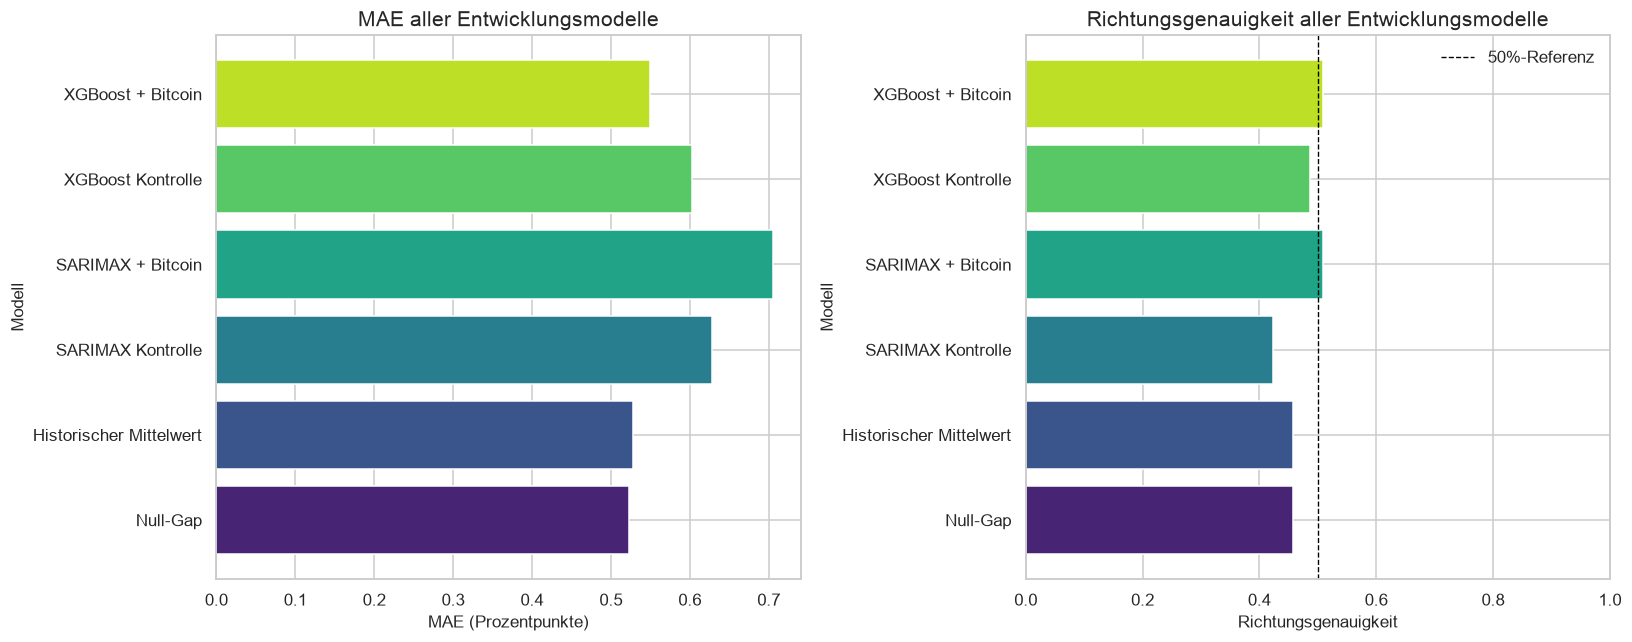

In [33]:
# Plot all implemented models in one consistently ordered comparison
all_model_order = [
    "Null-Gap",
    "Historischer Mittelwert",
    "SARIMAX Kontrolle",
    "SARIMAX + Bitcoin",
    "XGBoost Kontrolle",
    "XGBoost + Bitcoin",
]
all_model_colors = [
    VIRIDIS(position)
    for position in np.linspace(0.10, 0.90, len(all_model_order))
]
all_model_plot = all_model_metrics.set_index("Modell").loc[
    all_model_order
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].barh(
    all_model_order,
    all_model_plot["MAE (Prozentpunkte)"],
    color=all_model_colors,
)
axes[0].set_title("MAE aller Entwicklungsmodelle")
axes[0].set_xlabel("MAE (Prozentpunkte)")
axes[0].set_ylabel("Modell")
axes[0].set_xlim(left=0)

axes[1].barh(
    all_model_order,
    all_model_plot["Richtungsgenauigkeit"],
    color=all_model_colors,
)
axes[1].axvline(
    0.5,
    color="black",
    linewidth=0.9,
    linestyle="--",
    label="50%-Referenz",
)
axes[1].set_title("Richtungsgenauigkeit aller Entwicklungsmodelle")
axes[1].set_xlabel("Richtungsgenauigkeit")
axes[1].set_ylabel("Modell")
axes[1].set_xlim(0, 1)
axes[1].legend()

fig.tight_layout()
plt.show()

In [34]:
# Derive the XGBoost interpretation only from executed predictions
best_model_row = all_model_metrics.iloc[0]
xgboost_control_row = all_model_metrics.loc[
    all_model_metrics["Modell"] == "XGBoost Kontrolle"
].iloc[0]
xgboost_bitcoin_row = all_model_metrics.loc[
    all_model_metrics["Modell"] == "XGBoost + Bitcoin"
].iloc[0]
null_row = all_model_metrics.loc[
    all_model_metrics["Modell"] == "Null-Gap"
].iloc[0]

xgboost_mae_change = (
    xgboost_bitcoin_row["MAE (Prozentpunkte)"]
    - xgboost_control_row["MAE (Prozentpunkte)"]
)
xgboost_mae_effect = (
    "verbessert" if xgboost_mae_change < 0 else "verschlechtert"
)
xgboost_direction_change = (
    xgboost_bitcoin_row["Richtungsgenauigkeit"]
    - xgboost_control_row["Richtungsgenauigkeit"]
)
xgboost_direction_effect = (
    "steigt" if xgboost_direction_change >= 0 else "sinkt"
)
xgboost_null_mae_change = (
    xgboost_bitcoin_row["MAE (Prozentpunkte)"]
    - null_row["MAE (Prozentpunkte)"]
)
xgboost_null_comparison = (
    "unterbietet"
    if xgboost_null_mae_change < 0
    else "verfehlt"
)
xgboost_direction_years_above_reference = int(
    (
        xgboost_fold_metrics.loc[
            xgboost_fold_metrics["Modell"]
            == "XGBoost + Bitcoin",
            "Richtungsgenauigkeit",
        ]
        > 0.5
    ).sum()
)
xgboost_weakest_direction_row = xgboost_fold_metrics.loc[
    xgboost_fold_metrics["Modell"] == "XGBoost + Bitcoin"
].sort_values("Richtungsgenauigkeit").iloc[0]
xgboost_full_fold_metrics = xgboost_fold_metrics.loc[
    xgboost_fold_metrics["Modell"] == "XGBoost + Bitcoin",
    ["Validierungsjahr", "MAE (Prozentpunkte)"],
]
null_fold_metrics = all_model_fold_metrics.loc[
    all_model_fold_metrics["Modell"] == "Null-Gap",
    ["Validierungsjahr", "MAE (Prozentpunkte)"],
]
xgboost_null_fold_comparison = xgboost_full_fold_metrics.merge(
    null_fold_metrics,
    on="Validierungsjahr",
    suffixes=("_xgboost", "_null"),
)
xgboost_null_fold_wins = int(
    (
        xgboost_null_fold_comparison["MAE (Prozentpunkte)_xgboost"]
        < xgboost_null_fold_comparison["MAE (Prozentpunkte)_null"]
    ).sum()
)

xgboost_fold_winners = (
    xgboost_fold_metrics.sort_values("MAE (Prozentpunkte)")
    .groupby("Validierungsjahr")
    .first()["Modell"]
    .value_counts()
    .to_dict()
)
xgboost_fold_win_text = ", ".join(
    f"{model_name}: {win_count} von {len(VALIDATION_YEARS)} Jahren"
    for model_name, win_count in xgboost_fold_winners.items()
)
xgboost_evidence_text = (
    "Das ist noch kein robuster Nachweis für Prognosekraft: "
    "Der gepoolte MAE schlägt die Null-Gap-Baseline nicht und die "
    "Richtungsgenauigkeit liegt nur knapp über 50 %."
    if (
        xgboost_null_mae_change >= 0
        or xgboost_bitcoin_row["Richtungsgenauigkeit"] < 0.55
    )
    else "Das Ergebnis liefert ein über mehrere Folds sichtbares, aber "
    "noch im Holdout zu bestätigendes Prognosesignal."
)

display(
    Markdown(
        f'''
### Interpretation

Das beste Modell im bisherigen Entwicklungsvergleich ist
**{best_model_row['Modell']}** mit einem MAE von
**{best_model_row['MAE (Prozentpunkte)']:.3f} Prozentpunkten**.

Innerhalb von XGBoost {xgboost_mae_effect} die Ergänzung der
Bitcoin-Wochenendmerkmale den MAE um
**{abs(xgboost_mae_change):.3f} Prozentpunkte**. Die
Richtungsgenauigkeit {xgboost_direction_effect} um
**{100 * abs(xgboost_direction_change):.1f} Prozentpunkte** auf
**{xgboost_bitcoin_row['Richtungsgenauigkeit']:.1%}**. In
**{xgboost_direction_years_above_reference} von
{len(VALIDATION_YEARS)} Validierungsjahren** liegt sie über 50 %.
Im schwächsten Richtungsjahr
**{int(xgboost_weakest_direction_row['Validierungsjahr'])}** erreicht sie
allerdings nur
**{xgboost_weakest_direction_row['Richtungsgenauigkeit']:.1%}**.

`XGBoost + Bitcoin` {xgboost_null_comparison} die
Null-Gap-Baseline beim primären MAE um
**{abs(xgboost_null_mae_change):.3f} Prozentpunkte**. Foldweise schlägt
das vollständige Modell den Null-Gap in **{xgboost_null_fold_wins} von
{len(VALIDATION_YEARS)} Jahren**. Der direkte jährliche
XGBoost-Vergleich ergibt **{xgboost_fold_win_text}**.
Damit trennen wir einen möglichen Bitcoin-Zusatznutzen von der
allgemeinen Leistungsfähigkeit des nichtlinearen Modells.
{xgboost_evidence_text}
        '''
    )
)


### Interpretation

Das beste Modell im bisherigen Entwicklungsvergleich ist
**Null-Gap** mit einem MAE von
**0.522 Prozentpunkten**.

Innerhalb von XGBoost verbessert die Ergänzung der
Bitcoin-Wochenendmerkmale den MAE um
**0.054 Prozentpunkte**. Die
Richtungsgenauigkeit steigt um
**2.3 Prozentpunkte** auf
**50.8%**. In
**2 von
4 Validierungsjahren** liegt sie über 50 %.
Im schwächsten Richtungsjahr
**2021** erreicht sie
allerdings nur
**40.5%**.

`XGBoost + Bitcoin` verfehlt die
Null-Gap-Baseline beim primären MAE um
**0.027 Prozentpunkte**. Foldweise schlägt
das vollständige Modell den Null-Gap in **2 von
4 Jahren**. Der direkte jährliche
XGBoost-Vergleich ergibt **XGBoost + Bitcoin: 3 von 4 Jahren, XGBoost Kontrolle: 1 von 4 Jahren**.
Damit trennen wir einen möglichen Bitcoin-Zusatznutzen von der
allgemeinen Leistungsfähigkeit des nichtlinearen Modells.
Das ist noch kein robuster Nachweis für Prognosekraft: Der gepoolte MAE schlägt die Null-Gap-Baseline nicht und die Richtungsgenauigkeit liegt nur knapp über 50 %.
        

### 10.3 Welche Merkmale nutzt XGBoost?

Die Gain-Importance misst, wie stark ein Merkmal die Zielfunktion in
den trainierten Bäumen verbessert. Wir mitteln sie über alle
Walk-forward-Fits des vollständigen Modells. Die Darstellung zeigt
die interne Modellnutzung, aber weder Kausalität noch einen isolierten
Out-of-Sample-Beitrag. Dafür bleibt der Vergleich mit und ohne
Bitcoin entscheidend.

,Merkmal,Gruppe,Mittlere_Importance,Streuung
2,BTC-Wochenendrange,Bitcoin-Wochenende,0.1129,0.0062
12,QQQ-Volatilität 20 Tage,Kontrollmerkmal,0.0836,0.0030
1,BTC-Maximum-Drawdown,Bitcoin-Wochenende,0.0781,0.0091
3,BTC-Wochenendrendite,Bitcoin-Wochenende,0.0738,0.0142
13,VIX-Veränderung 5 Tage,Kontrollmerkmal,0.0731,0.0096
14,VIX-Schlusswert,Kontrollmerkmal,0.0705,0.0046
9,Mittel der letzten 4 regulären Gaps,Kontrollmerkmal,0.0683,0.0096
6,DXY-Tagesrendite,Kontrollmerkmal,0.0655,0.0046
10,QQQ-Momentum 5 Tage,Kontrollmerkmal,0.0579,0.0093
8,Letzter regulärer QQQ-Gap,Kontrollmerkmal,0.0560,0.0043


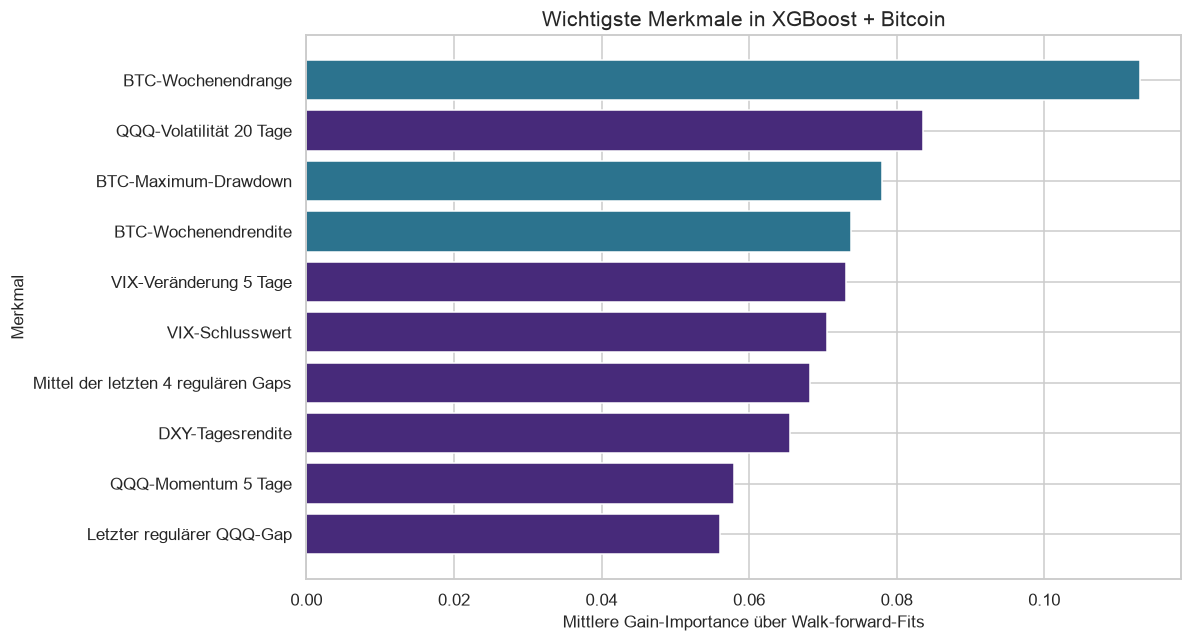

In [35]:
# Summarize model usage across all full-model walk-forward fits
full_model_importance = xgboost_feature_importance[
    xgboost_feature_importance["model"] == "XGBoost + Bitcoin"
].copy()
importance_summary = (
    full_model_importance.groupby("feature", as_index=False)
    .agg(
        Mittlere_Importance=("gain_importance", "mean"),
        Streuung=("gain_importance", "std"),
    )
    .sort_values("Mittlere_Importance", ascending=False)
)
importance_summary["Gruppe"] = np.where(
    importance_summary["feature"].isin(BITCOIN_FEATURES),
    "Bitcoin-Wochenende",
    "Kontrollmerkmal",
)

feature_labels = {
    "qqq_gap_lag_1": "Letzter regulärer QQQ-Gap",
    "qqq_gap_mean_4": "Mittel der letzten 4 regulären Gaps",
    "qqq_return_1d": "QQQ-Freitagsrendite",
    "qqq_momentum_5d": "QQQ-Momentum 5 Tage",
    "qqq_volatility_20d": "QQQ-Volatilität 20 Tage",
    "fear_greed": "Fear & Greed",
    "vix_close": "VIX-Schlusswert",
    "vix_change_5d": "VIX-Veränderung 5 Tage",
    "dxy_return_1d": "DXY-Tagesrendite",
    "dxy_change_5d": "DXY-Veränderung 5 Tage",
    "btc_weekend_return": "BTC-Wochenendrendite",
    "btc_weekend_rv": "BTC-Wochenendvolatilität",
    "btc_weekend_range": "BTC-Wochenendrange",
    "btc_weekend_log_volume": "BTC-Wochenendvolumen",
    "btc_weekend_max_drawdown": "BTC-Maximum-Drawdown",
}
importance_summary["Merkmal"] = importance_summary["feature"].map(
    feature_labels
)
top_importance = importance_summary.head(10).sort_values(
    "Mittlere_Importance"
)

display(
    importance_summary[
        ["Merkmal", "Gruppe", "Mittlere_Importance", "Streuung"]
    ].head(10).round(4)
)

importance_colors = [
    COLORS["btc"] if group == "Bitcoin-Wochenende" else VIRIDIS(0.12)
    for group in top_importance["Gruppe"]
]
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(
    top_importance["Merkmal"],
    top_importance["Mittlere_Importance"],
    color=importance_colors,
)
ax.set_title("Wichtigste Merkmale in XGBoost + Bitcoin")
ax.set_xlabel("Mittlere Gain-Importance über Walk-forward-Fits")
ax.set_ylabel("Merkmal")
ax.set_xlim(left=0)
fig.tight_layout()
plt.show()

In [36]:
# Compare group usage without treating importance as causal evidence
full_model_group_importance = (
    full_model_importance.assign(
        group=np.where(
            full_model_importance["feature"].isin(BITCOIN_FEATURES),
            "Bitcoin-Wochenende",
            "Kontrollmerkmale",
        )
    )
    .groupby(["forecast_date", "group"], as_index=False)[
        "gain_importance"
    ]
    .sum()
)
bitcoin_importance_share = full_model_group_importance.loc[
    full_model_group_importance["group"] == "Bitcoin-Wochenende",
    "gain_importance",
].mean()
equal_feature_share = len(BITCOIN_FEATURES) / len(FULL_FEATURES)
top_feature_names = ", ".join(
    importance_summary.head(3)["Merkmal"].tolist()
)

display(
    Markdown(
        f'''
### Interpretation

Die drei Merkmale mit der höchsten mittleren Gain-Importance sind
**{top_feature_names}**. Zusammen erhalten die fünf
Bitcoin-Wochenendmerkmale im vollständigen Modell durchschnittlich
**{bitcoin_importance_share:.1%} der Importance**. Bei einer gleichmässigen
Verteilung über alle {len(FULL_FEATURES)} Merkmale würden auf die fünf
Bitcoin-Variablen **{equal_feature_share:.1%}** entfallen. Die gemessene
Importance zeigt daher Nutzung, aber keine klare Dominanz dieser Gruppe.

Ob die Bitcoin-Nutzung ausserhalb des Trainings nützlich ist, entscheidet
ausschliesslich der zuvor gezeigte Walk-forward-Vergleich mit dem
Kontrollmodell; Gain-Importance ist kein Kausalitätsnachweis.
        '''
    )
)


### Interpretation

Die drei Merkmale mit der höchsten mittleren Gain-Importance sind
**BTC-Wochenendrange, QQQ-Volatilität 20 Tage, BTC-Maximum-Drawdown**. Zusammen erhalten die fünf
Bitcoin-Wochenendmerkmale im vollständigen Modell durchschnittlich
**36.9% der Importance**. Bei einer gleichmässigen
Verteilung über alle 15 Merkmale würden auf die fünf
Bitcoin-Variablen **33.3%** entfallen. Die gemessene
Importance zeigt daher Nutzung, aber keine klare Dominanz dieser Gruppe.

Ob die Bitcoin-Nutzung ausserhalb des Trainings nützlich ist, entscheidet
ausschliesslich der zuvor gezeigte Walk-forward-Vergleich mit dem
Kontrollmodell; Gain-Importance ist kein Kausalitätsnachweis.
        

## 11. Zwischenfazit und nächster Schritt

### Interpretation

Mit XGBoost ist neben der statistischen SARIMAX-Methode auch ein
klassisches nichtlineares Machine-Learning-Modell umgesetzt. Beide
Verfahren verwenden dieselben Daten, Feature-Sets, Prognosetermine
und Metriken.

Als nächstes ergänzen wir Chronos-2 als vortrainiertes Foundation
Model. Der Holdout ab 2025 bleibt weiterhin gesperrt und wird erst
nach Abschluss der Modellentwicklung einmalig ausgewertet.